# Normalisasi Konsep Medis Lintas Bahasa yang Efisien Parameter untuk Bahasa Indonesia: Perbandingan *Full Fine-Tuning* dan QLoRA pada *Self-Alignment Pretraining*

**Judul:**Normalisasi Konsep Medis Lintas Bahasa yang Efisien Parameter untuk Bahasa Indonesia: Perbandingan Full Fine-Tuning dan QLoRA pada Self-Alignment Pretraining**  
**Acuan penelitian:** Liu dkk. (2021), *Learning Domain-Specialised Representations for Cross-Lingual Biomedical Entity Linking*  
**Kelompok:** 12
**Status evaluasi Indonesia:** benchmark *silver* terjemahan mesin, bukan label medis yang diverifikasi pakar.

Notebook menyatukan **persiapan data**, **Eksperimen 1 (UMLS 2026AA: Full FT vs QLoRA)**, **Eksperimen 2 (MUSE/WikiTitles/gabungan)**, **evaluasi**, **analisis**, dan **ekspor model**. Potongan training mempertahankan logika dan pengaturan utama notebook eksperimen yang telah digunakan. Nama/path sengaja diseragamkan untuk penggunaan kembali checkpoint di Drive.

## Daftar Isi
1. [Latar belakang](#latar-belakang)
2. [Tujuan dan pertanyaan penelitian](#tujuan)
3. [Sumber dan karakteristik dataset](#dataset)
4. [Metodologi dan eksperimen](#metodologi)
   - [4.1 Instalasi dan lingkungan](#setup)
   - [4.2 Data preparation](#preparation)
   - [4.3 Eksperimen 1 — UMLS 2026AA](#exp1)
   - [4.4 Eksperimen 2 — Transfer bilingual](#exp2)
5. [Hasil dan evaluasi](#hasil)
6. [Diskusi](#diskusi)
7. [Kesimpulan](#kesimpulan)
8. [Future works](#futureworks)
9. [Output dan download model](#output)

<a id="latar-belakang"></a>
## 1. Latar Belakang

Istilah biomedis dapat dituliskan sebagai singkatan, sinonim, atau istilah dari bahasa berbeda. *Biomedical entity linking* menyelaraskan sebuah sebutan dengan **Concept Unique Identifier (CUI)** UMLS melalui pencarian representasi vektor pada kamus kandidat. Bahasa Indonesia tidak tercakup dalam XL-BEL v0.0 yang menjadi acuan reproduksi Liu dkk. (2021). Penelitian ini mengadaptasi **XLM-R + Self-Alignment Pretraining (SAP)** dan meninjau apakah **QLoRA** dapat mengurangi biaya penyesuaian model.

Dalam penelitian ini, penerjemahan XL-BEL EN→ID digunakan **hanya untuk membangun data uji silver**. Sebaliknya, MUSE dan WikiTitles adalah pasangan teks paralel untuk **pelatihan lanjutan**. Model tidak menggunakan penerjemah pada saat *entity linking*.

<a id="tujuan"></a>
## 2. Tujuan dan Pertanyaan Penelitian

1. Mereproduksi sebagian hasil Liu dkk. (2021) pada XL-BEL Mandarin (ZH) dan Thailand (TH), kemudian mengadaptasi SAP UMLS 2026AA untuk Indonesia.
2. Membuat benchmark silver Indonesia dari 1.000 *mentions* Inggris, dengan rekonstruksi serta penyaringan menjadi 880 frasa.
3. Membandingkan **Full Fine-Tuning** dan **QLoRA**, serta efek transfer **MUSE**, **WikiTitles**, dan **gabungan keduanya**.
4. Menilai ketepatan retrieval dengan P@1, P@5, MRR dan mencatat efisiensi sumber daya.

**RQ1:** Seberapa baik SAP memetakan frasa Indonesia ke CUI UMLS?  
**RQ2:** Berapa kompromi akurasi dan sumber daya antara Full FT dan QLoRA?  
**RQ3:** Bagaimana perbedaan efek MUSE dan WikiTitles, dan mengapa hasil Thailand dan Indonesia tidak boleh dibandingkan secara kausal tanpa protokol identik?

<a id="dataset"></a>
## 3. Dataset, Asal Data, dan Lisensi

| Sumber | Peran | Karakteristik |
|:--|:--|:--|
| XL-BEL v0.0 EN | Sumber 1.000 frasa yang diterjemahkan | Label CUI asal tetap dipertahankan sebagai acuan sementara |
| MarianMT `Helsinki-NLP/opus-mt-en-id` | Penerjemah otomatis EN→ID | Model *encoder–decoder*, **beam search 4** |
| Benchmark silver ID | Evaluasi utama | **880 frasa**, belum diverifikasi dokter/pakar; format `CUI||frasa` |
| Kamus XL-BEL WikiMed | Kamus retrieval tetap | **399.931 nama kandidat**; sama untuk seluruh evaluasi Indonesia |
| UMLS 2026AA MRCONSO | Sinonim untuk SAP | Materi **berlisensi**, tidak disertakan di GitHub atau paket ekspor |
| MUSE EN–ID | Data pelatihan transfer | Kamus pasangan kata EN–ID Meta AI |
| WikiTitles EN–ID | Data pelatihan transfer | Judul artikel EN–ID dipasangkan berdasarkan **Wikidata QID**, snapshot 30 Maret 2026 |

**Pemisahan:** evaluasi memakai silver ID, pelatihan SAP memakai UMLS, dan eksperimen transfer memakai MUSE/WikiTitles. Kamus kandidat tidak disubstitusi dengan dump UMLS baru agar seluruh konfigurasi dievaluasi pada ruang pencarian yang sama.

Referensi: [SapBERT](https://github.com/cambridgeltl/sapbert) · [MUSE](https://github.com/facebookresearch/MUSE) · [Wikimedia/Wikidata Titles](https://huggingface.co/datasets/wikimedia/wikidata-title-desc) · [MarianMT EN–ID](https://huggingface.co/Helsinki-NLP/opus-mt-en-id) · [UMLS NLM](https://www.nlm.nih.gov/research/umls/).

<a id="metodologi"></a>
## 4. Metodologi dan Eksperimen

**Alur:** XL-BEL EN → MarianMT EN–ID → audit CUI/ambiguitas/duplikasi → silver ID 880 frasa; UMLS 2026AA → pasangan sinonim → 10 shard → XLM-R + SAP Full FT / QLoRA → checkpoint SAP; MUSE/WikiTitles/gabungan → pelatihan lanjutan masing-masing checkpoint → encoding CLS → dot-product pada 399.931 nama → P@1/P@5/MRR.

Skor retrieval dihitung sebagai $s(q,d)=h_{\mathrm{CLS}}(q)^\top h_{\mathrm{CLS}}(d)$. Prediksi benar bila salah satu **CUI** gold muncul di antara kandidat pada peringkat yang dilaporkan.

### Tahap yang harus dipahami sebelum menjalankan

- **Data preparation:** gunakan ulang berkas Drive jika sudah tersimpan. UMLS wajib diakses dengan lisensi NLM.
- **Eksperimen 1:** satu mode (`full` atau `qlora`) per eksekusi; training 10 shard dan *resume* di batas shard.
- **Eksperimen 2:** enam kombinasi mode × dataset; memakai checkpoint SAP masing-masing, tidak memulai ulang dari XLM-R mentah.
- **Evaluasi:** hasil benchmark silver tidak setara dengan validasi klinis atau akurasi pada laporan pasien asli.

<a id="setup"></a>
### 4.1 Instalasi dan lingkungan Colab

**Jalankan sekali** di sesi Colab yang akan dipakai. Setelah instalasi, jika muncul peringatan modul sudah pernah diimpor, pilih **Runtime → Restart session** dan mulai dari sel konfigurasi. Paket dipin untuk menyatukan notebook persiapan data, Eksperimen 1, dan Eksperimen 2. Notebook asal memakai versi `bitsandbytes` yang berbeda antar-eksperimen (0.46.0 pada Exp1 dan 0.50.2 pada Exp2); penggunaan versi tunggal di bawah untuk *rerun* perlu dicatat sebagai perbedaan lingkungan dari catatan eksperimen lama.

In [2]:
%pip -q install "transformers==4.52.4" "peft==0.15.2" "accelerate==1.8.1" "bitsandbytes==0.50.2" "pytorch-metric-learning==2.9.0" "wandb==0.20.1" "safetensors>=0.5.3,<1" "sentencepiece>=0.2,<1" "sacremoses>=0.1,<1" "huggingface-hub>=0.30,<1" "duckdb>=1.1,<2" "hf_xet>=1,<2" "pandas>=2.2,<3" "numpy>=1.26,<3" "requests>=2.31,<3" "tqdm>=4.60,<5" "matplotlib>=3.8,<4"

<a id="preparation"></a>
### 4.2 Persiapan data Indonesia

Bagian ini berasal dari `kc_data_preparation`: mount Drive, unduh XL-BEL dan MUSE, rekonstruksi WikiTitles, buat pasangan paralel, lakukan MarianMT, ambil MRCONSO berlisensi, bentuk pasangan SAP, lalu hasilkan silver 880 frasa. Data mentah dan manifest dipertahankan terpisah dari model.

#### 4.2.1 Mount Drive dan folder kerja

In [3]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, csv, io, json, re, hashlib, shutil, subprocess, sys, time, zipfile, gzip, sqlite3, random
from datetime import datetime, timezone

ROOT = Path('/content/drive/MyDrive/sapbert_id_kc_paper_2026AA')
assert ROOT.name == 'sapbert_id_kc_paper_2026AA'
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed_candidates'
TRAIN_FINAL = ROOT / 'data' / 'train_final_after_review'
BENCH = ROOT / 'benchmark'
PRIVATE = ROOT / 'restricted_umls_2026aa'
RESTRICTED = PRIVATE
META = ROOT / 'metadata'
RUNS = ROOT / 'runs'
for p in (RAW/'muse', RAW/'wikititles', RAW/'xlbel', PROCESSED, TRAIN_FINAL,
          BENCH, PRIVATE/'archive', PRIVATE/'sap_pairs', PRIVATE/'dictionary', META, RUNS):
    p.mkdir(parents=True, exist_ok=True)

(ROOT/'README_DATA_POLICY.txt').write_text(
    'Proyek paper Indonesia. File restricted_umls_2026aa berlisensi UMLS: '
    'jangan commit/publikasikan. Dataset test ID hanya gold setelah validasi manusia. '
    'Folder ini terpisah dari sapbert_ngurah dan bertkc.\n', encoding='utf-8')
print('ROOT independen:', ROOT)
print('Disk lokal Colab tersedia: %.1f GiB' % (shutil.disk_usage('/content').free/1024**3))
print('Tidak membaca/mengubah shortcut sapbert_ngurah maupun folder bertkc.')

Mounted at /content/drive
ROOT independen: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA
Disk lokal Colab tersedia: 235.2 GiB
Tidak membaca/mengubah shortcut sapbert_ngurah maupun folder bertkc.


#### 4.2.2 Sumber XL-BEL EN dan kamus resmi

In [4]:
import requests
XL_REPO = 'https://raw.githubusercontent.com/cambridgeltl/sapbert/1a528f66d277d91f99b6463b43ce5309a9279506'
URL_XLBEL_EN = XL_REPO+'/evaluation/xl_bel/xlbel_v0.0/en_1k_test_query.txt'
URL_XLBEL_DICT = XL_REPO+'/evaluation/xl_bel/umls_onto_all_lang_cased_wikimed_only_399931.txt'
XLBEL_EN = RAW/'xlbel'/'en_1k_test_query.txt'
XLBEL_DICT = RAW/'xlbel'/'umls_onto_all_lang_cased_wikimed_only_399931.txt'

def digest(path, alg='sha256'):
    h=hashlib.new(alg)
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(4*1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def sha256(path): return digest(path,'sha256')

def download_once(url, path):
    path=Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.is_file() and path.stat().st_size > 0:
        print('Ada (skip):',path.name); return
    tmp=path.with_suffix(path.suffix+'.part')
    try:
        with requests.get(url, stream=True, timeout=(25,180)) as r:
            r.raise_for_status()
            with tmp.open('wb') as f:
                for chunk in r.iter_content(chunk_size=1024*1024):
                    if chunk:f.write(chunk)
    except requests.RequestException as exc:
        raise RuntimeError('Unduh sumber publik gagal: '+path.name) from None
    if not tmp.exists() or tmp.stat().st_size==0:raise RuntimeError('Unduhan kosong '+path.name)
    os.replace(tmp,path)
    print('OK:',path.name, f'{path.stat().st_size/1024**2:.1f} MiB')

download_once(URL_XLBEL_EN, XLBEL_EN)
download_once(URL_XLBEL_DICT, XLBEL_DICT)
raw_lines=[line.strip() for line in XLBEL_EN.read_text(encoding='utf-8').splitlines() if line.strip()]
parsed=[]
for i,line in enumerate(raw_lines,1):
    p=line.split('||',1)
    if len(p)!=2 or not p[0].strip() or not p[1].strip():
        raise ValueError('XL-BEL: format salah di baris '+str(i))
    parsed.append((i,p[0].strip(),p[1].strip()))
assert len(parsed)==1000, 'Jumlah XL-BEL English tidak 1000. Periksa versi file asli.'
print('XL-BEL EN 1k:',len(parsed),'| dictionary baris:',sum(1 for _ in XLBEL_DICT.open(encoding='utf-8')))
(META/'xlbel_source.json').write_text(json.dumps({
    'repository_commit':'1a528f66d277d91f99b6463b43ce5309a9279506',
    'language':'en','test_mention_count':len(parsed),
    'test_sha256':sha256(XLBEL_EN),'dictionary_sha256':sha256(XLBEL_DICT),
    'downloaded_utc':datetime.now(timezone.utc).isoformat()
},indent=2),encoding='utf-8')

Ada (skip): en_1k_test_query.txt
Ada (skip): umls_onto_all_lang_cased_wikimed_only_399931.txt
XL-BEL EN 1k: 1000 | dictionary baris: 399931


351

#### 4.2.3 Worksheet terjemahan dan status review

Worksheet menyimpan frasa Inggris, CUI referensi, hasil MT, dan kolom yang nantinya dapat digunakan untuk peninjauan manual. **Tidak ada pengesahan label emas otomatis.**

In [5]:
REVIEW_CSV=BENCH/'id_xlbel_translation_review.csv'
FIELDS=['source_line','gold_cui','english_mention','indonesian_mt_draft',
        'indonesian_reviewed','review_status','cui_2026_verified','reviewer','notes']
if REVIEW_CSV.exists():
    print('Review sudah ada, TIDAK ditimpa:',REVIEW_CSV)
else:
    with REVIEW_CSV.open('w',encoding='utf-8-sig',newline='') as f:
        w=csv.DictWriter(f,fieldnames=FIELDS);w.writeheader()
        for i,cui,en in parsed:
            w.writerow({'source_line':i,'gold_cui':cui,'english_mention':en,
                'indonesian_mt_draft':'','indonesian_reviewed':'',
                'review_status':'pending','cui_2026_verified':'no','reviewer':'','notes':''})
    print('Template tercipta:',REVIEW_CSV)
print('Jumlah calon mention:',len(parsed),'— BELUM gold Indonesia.')

Review sudah ada, TIDAK ditimpa: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/benchmark/id_xlbel_translation_review.csv
Jumlah calon mention: 1000 — BELUM gold Indonesia.


#### 4.2.4 Unduh MUSE EN–ID

Sumber MUSE: `https://dl.fbaipublicfiles.com/arrival/dictionaries/en-id.txt`. Unduhan di-*skip* bila file sudah ada.

In [6]:
MUSE_URLS = {
    'en-id.txt': 'https://dl.fbaipublicfiles.com/arrival/dictionaries/en-id.txt',
    'en-id.0-5000.txt':'https://dl.fbaipublicfiles.com/arrival/dictionaries/en-id.0-5000.txt',
    'en-id.5000-6500.txt':'https://dl.fbaipublicfiles.com/arrival/dictionaries/en-id.5000-6500.txt'
}
for filename,url in MUSE_URLS.items():
    download_once(url, RAW/'muse'/filename)
    print(filename, 'SHA256', sha256(RAW/'muse'/filename))

Ada (skip): en-id.txt
en-id.txt SHA256 b20b75f038ef95c31d5cc993c75843bffad0ce6534bbe1e44aeeb588a7b56637
Ada (skip): en-id.0-5000.txt
en-id.0-5000.txt SHA256 2a8b35b77c2ba81e6b7a98f3ea6bc46bdd0a817f9a6aad039a20dc7b54f7cf93
Ada (skip): en-id.5000-6500.txt
en-id.5000-6500.txt SHA256 532572a46024de6cb5db4103b4eb16163ca671a00703522134bc8bb90938b7ad


#### 4.2.5 Unduh dan bentuk WikiTitles EN–ID

Dari dataset `wikimedia/wikidata-title-desc`, judul Inggris dan Indonesia digabung menggunakan QID yang sama; hasilnya **rekonstruksi** snapshot 2026, bukan salinan WikiTitles 2021.

In [7]:
WIKIDATA_REPO='wikimedia/wikidata-title-desc'
WIKIDATA_REV='454af97fe6ac5b868562f5bc8085e411bae8cffd'  # snapshot 2026-03-30, pinned HF commit
PARQUET_LOCAL=Path('/content/wikidata_title_desc_en_id_parquet')
WT_RAW=RAW/'wikititles'/'wt_en_id_reconstructed_20260330.txt'
WT_META=META/'wt_en_id_reconstructed_20260330.metadata.json'


def wt_is_valid():
    if not (WT_RAW.is_file() and WT_META.is_file()): return False
    m=json.loads(WT_META.read_text(encoding='utf-8'))
    return (m.get('revision')==WIKIDATA_REV and m.get('sha256')==sha256(WT_RAW))

if wt_is_valid():
    print('WikiTitles EN–ID sudah valid di Drive. Download Parquet dilewati.')
else:
    from huggingface_hub import HfApi, hf_hub_download
    api=HfApi()
    files=api.list_repo_files(WIKIDATA_REPO,repo_type='dataset',revision=WIKIDATA_REV)
    EN_NAMES=sorted(x for x in files if x.startswith('data/en/') and x.endswith('.parquet'))
    ID_NAMES=sorted(x for x in files if x.startswith('data/id/') and x.endswith('.parquet'))
    assert EN_NAMES and ID_NAMES, 'EN / ID tidak tersedia pada revision yang dipilih.'

    def get_parquets(names):
        out=[]
        for name in names:
            path=hf_hub_download(repo_id=WIKIDATA_REPO,filename=name,repo_type='dataset',
                                 revision=WIKIDATA_REV,local_dir=str(PARQUET_LOCAL))
            out.append(str(path))
            print('Downloaded/cached',name, round(Path(path).stat().st_size/1024**2,1),'MB')
        return out

    EN_PARQUET=get_parquets(EN_NAMES)
    ID_PARQUET=get_parquets(ID_NAMES)

WikiTitles EN–ID sudah valid di Drive. Download Parquet dilewati.


In [8]:
if wt_is_valid():
    print('Tidak perlu rekonstruksi ulang:', WT_RAW)
else:
    import duckdb
    assert 'EN_PARQUET' in globals() and 'ID_PARQUET' in globals(), 'Jalankan sel download Parquet dulu'
    con=duckdb.connect(database=':memory:')
    con.execute("SET memory_limit='4GB'")
    temp_dir=Path('/content/wikidata_duckdb_tmp')
    temp_dir.mkdir(exist_ok=True)
    con.execute(f"SET temp_directory='{temp_dir.as_posix()}'")

    sql="""SELECT e.qid, e.title AS en_title, t.id_title
    FROM read_parquet(?) e
    JOIN (
      SELECT qid, min(title) AS id_title
      FROM read_parquet(?)
      WHERE lang='id' AND qid IS NOT NULL AND title IS NOT NULL
      GROUP BY qid
    ) t ON e.qid=t.qid
    WHERE e.lang='en' AND e.title IS NOT NULL
    ORDER BY e.qid, e.title"""
    result=con.execute(sql,[EN_PARQUET,ID_PARQUET])
    tmp=WT_RAW.with_name(WT_RAW.name+'.part')
    seen=set(); n=0; rejected=0
    exclude_en=('Category:','Template:','File:','Wikipedia:','Help:','Portal:','Draft:',
                'Module:','User:','Talk:')
    exclude_id=('Kategori:','Templat:','Template:','Berkas:','File:','Wikipedia:',
                'Bantuan:','Portal:','Modul:','Pengguna:','Pembicaraan:')
    with tmp.open('w',encoding='utf-8') as f:
        while True:
            rows=result.fetchmany(10000)
            if not rows: break
            for qid,en,idn in rows:
                if not isinstance(qid,str) or not re.fullmatch(r'Q[0-9]+',qid): rejected+=1;continue
                if qid in seen:continue
                if not isinstance(en,str) or not isinstance(idn,str):rejected+=1;continue
                en=' '.join(en.split()); idn=' '.join(idn.split())
                if not en or not idn or '||' in en or '||' in idn:rejected+=1;continue
                if en.startswith(exclude_en) or idn.startswith(exclude_id):rejected+=1;continue
                f.write(f'WTEN_ID_{qid}||{en}||{idn}\n')
                seen.add(qid);n+=1
                if n % 100000 == 0: print('Pasangan rekonstruksi:', format(n,','))
    con.close()
    if n<=0: raise RuntimeError('Tidak ditemukan pasangan judul EN–ID. Cek query dan file Parquet.')
    os.replace(tmp,WT_RAW)
    meta={
        'source':WIKIDATA_REPO,'revision':WIKIDATA_REV,'language_pair':'en-id',
        'join_key':'qid','filter':'namespace prefixes and empty titles',
        'method':'one EN/ID title pair per Wikidata QID, not the original Liu WikiTitles',
        'pairs':n,'rejected':rejected,'sha256':sha256(WT_RAW),
        'format':'WTEN_ID_QID||English title||Indonesian title',
        'created_utc':datetime.now(timezone.utc).isoformat(),
    }
    WT_META.write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
    print('DONE',n,'pairs:', WT_RAW)
print('VALID:',wt_is_valid())

Tidak perlu rekonstruksi ulang: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/data/raw/wikititles/wt_en_id_reconstructed_20260330.txt
VALID: True


#### 4.2.6 Format pasangan untuk transfer SAP

MUSE dan WikiTitles disimpan sebagai `pseudo_label||English||Indonesian`, lalu dibuat kombinasi tanpa duplikasi pasangan. Label ini **bukan CUI**.

In [9]:
MUSE_PAIRS=PROCESSED/'muse_en_id_pairs.txt'
WT_PAIRS=PROCESSED/'wt_en_id_pairs.txt'
BOTH_PAIRS=PROCESSED/'wt_plus_muse_en_id_pairs.txt'


def clean_text(s): return ' '.join(s.strip().split())


def build_muse():
    path=RAW/'muse'/'en-id.txt'
    if not path.exists(): raise FileNotFoundError(path)
    temp=MUSE_PAIRS.with_name(MUSE_PAIRS.name+'.part')
    seen=set(); valid=0; bad=0
    with path.open(encoding='utf-8') as inp, temp.open('w',encoding='utf-8') as out:
        for line in inp:
            bits=line.strip().split()
            if len(bits)!=2: bad+=1;continue
            en,idn=(clean_text(s) for s in bits)
            key=(en,idn)
            if not en or not idn or '||' in en or '||' in idn or key in seen: continue
            seen.add(key);valid+=1
            out.write(f'MUSE_EN_ID_{valid:08d}||{en}||{idn}\n')
    os.replace(temp,MUSE_PAIRS)
    return {'pairs':valid,'malformed_lines':bad,'sha256':sha256(MUSE_PAIRS)}


def copy_wt_pairs():
    assert wt_is_valid(), 'WikiTitles harus valid dulu'
    shutil.copyfile(WT_RAW,WT_PAIRS)
    n=sum(1 for _ in WT_PAIRS.open(encoding='utf-8'))
    return {'pairs':n,'sha256':sha256(WT_PAIRS)}


def combine_pairs():
    temp=BOTH_PAIRS.with_name(BOTH_PAIRS.name+'.part')
    seen=set(); n=0; duplicates=0
    with temp.open('w',encoding='utf-8') as out:
        for path in (MUSE_PAIRS,WT_PAIRS):
            with path.open(encoding='utf-8') as inp:
                for line in inp:
                    bits=line.rstrip('\n').split('||',2)
                    if len(bits)!=3:raise ValueError('Format tidak valid '+path.name)
                    key=(clean_text(bits[1]).casefold(),clean_text(bits[2]).casefold())
                    if key in seen:duplicates+=1;continue
                    seen.add(key);out.write(line);n+=1
    os.replace(temp,BOTH_PAIRS)
    return {'pairs':n,'cross_source_duplicates':duplicates,'sha256':sha256(BOTH_PAIRS)}

m1=build_muse();m2=copy_wt_pairs();m3=combine_pairs()
manifest={'muse':m1,'wikititles':m2,'wt_plus_muse':m3,'sources':{
    'muse':'Meta MUSE en-id full dictionary',
    'wikititles':'wikimedia/wikidata-title-desc snapshot-2026-03-30'},
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'warning':'Candidates only; run leakage audit after gold annotation before training'}
(META/'bitext_candidate_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(manifest,ensure_ascii=False,indent=2))

{
  "muse": {
    "pairs": 96500,
    "malformed_lines": 0,
    "sha256": "d36d48eab6eea4fa7e51bdc7a283e313d50e58d93937c637d3340f3e6c127fda"
  },
  "wikititles": {
    "pairs": 473796,
    "sha256": "1a6affc52a2aba734afc73e1a6a986933dc1f9cdf4e35b410f4a8ffb2da35db4"
  },
  "wt_plus_muse": {
    "pairs": 555546,
    "cross_source_duplicates": 14750,
    "sha256": "367c1080a6caabe0189389c3ab25cc13954bac9d2e5173d5fe6ff7d4ac303f62"
  },
  "sources": {
    "muse": "Meta MUSE en-id full dictionary",
    "wikititles": "wikimedia/wikidata-title-desc snapshot-2026-03-30"
  },
  "created_utc": "2026-11-20T06:03:46.448155+00:00",
  "warning": "Candidates only; run leakage audit after gold annotation before training"
}


#### 4.2.7 Rekonstruksi 1.000 frasa: MarianMT + beam search

Model **`Helsinki-NLP/opus-mt-en-id`** memakai Transformer encoder–decoder. Kode asli memproses per batch **16**, `max_length=64`, `max_new_tokens=80`, dan `num_beams=4`. Terjemahan otomatis hanya *draft*; *beam search* bukan model terjemahan yang berbeda dari MarianMT.

Untuk menggunakan worksheet yang sudah terisi, biarkan `RUN_MT=False`. Set `True` jika baru menyiapkan data dari awal.

In [10]:
RUN_MT = False
if RUN_MT:
    from importlib.metadata import version
    from packaging.version import Version
    tr_v = Version(version('transformers'))
    hub_v = Version(version('huggingface-hub'))
    if tr_v.major >= 5 and hub_v < Version('1.31.0'):
        raise RuntimeError(
            f'Dependensi tidak kompatibel: transformers={tr_v}, huggingface-hub={hub_v}. '
            'Jalankan A0 lalu Runtime → Restart session, kemudian ulangi A1 sampai A7.'
        )
    print('Versi MT:', 'transformers='+str(tr_v), 'huggingface-hub='+str(hub_v))
    import torch
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    mt_id='Helsinki-NLP/opus-mt-en-id'
    tokenizer=AutoTokenizer.from_pretrained(mt_id)
    mt_model=AutoModelForSeq2SeqLM.from_pretrained(mt_id)
    device='cuda' if torch.cuda.is_available() else 'cpu'
    mt_model=mt_model.to(device).eval()
    with REVIEW_CSV.open(encoding='utf-8-sig',newline='') as f:
        rows=list(csv.DictReader(f))
    todo=[i for i,row in enumerate(rows) if not row['indonesian_mt_draft'].strip()]
    print('Penerjemahan draft:',len(todo),'baris pada',device)
    if todo:
        backup=BENCH/f'review_before_mt_{datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")}.csv'
        shutil.copy2(REVIEW_CSV,backup)
        for start in range(0,len(todo),16):
            batch_idx=todo[start:start+16]
            texts=[rows[i]['english_mention'] for i in batch_idx]
            enc=tokenizer(texts,return_tensors='pt',padding=True,truncation=True,max_length=64).to(device)
            with torch.inference_mode():
                output_ids=mt_model.generate(**enc,max_new_tokens=80,num_beams=4)
            results=tokenizer.batch_decode(output_ids,skip_special_tokens=True)
            for i,translation in zip(batch_idx,results):
                rows[i]['indonesian_mt_draft']=translation.strip()
            if (start//16+1)%10==0 or start+16 >= len(todo):
                tmp=REVIEW_CSV.with_name(REVIEW_CSV.name+'.part')
                with tmp.open('w',newline='',encoding='utf-8-sig') as f:
                    w=csv.DictWriter(f,fieldnames=FIELDS);w.writeheader();w.writerows(rows)
                os.replace(tmp,REVIEW_CSV)
                print('Simpan draft sampai indeks:',start+len(batch_idx),'/',len(todo))
        (META/'mt_model.json').write_text(json.dumps({'model':mt_id,'source':'en','target':'id',
          'model_revision':getattr(mt_model.config,'_commit_hash',None),
          'generated_utc':datetime.now(timezone.utc).isoformat()},indent=2),encoding='utf-8')
        print('Draft MT tersedia; MASIH perlu review manusia:',REVIEW_CSV)
else:
    print('Terjemahan otomatis belum dijalankan; ubah RUN_MT=True jika diperlukan.')

Terjemahan otomatis belum dijalankan; ubah RUN_MT=True jika diperlukan.


#### 4.2.8 Unduh MRCONSO UMLS 2026AA (terbatas/lisensi)

Masukkan API key melalui **Colab Secrets → `UMLS_API_KEY`**. Jangan menulis API key langsung pada notebook. Hanya folder `restricted_umls_2026aa/` yang menyimpan data UMLS berlisensi. Set `RUN_UMLS_DOWNLOAD=True` hanya jika arsip belum tersimpan.

In [11]:
RELEASE_VERSION='2026AA'  # PIN, jangan otomatis ambil current (bisa 2026AB)
RELEASE_TYPE='umls-metathesaurus-mrconso-file'
RELEASES_ENDPOINT='https://uts-ws.nlm.nih.gov/releases'
DOWNLOAD_ENDPOINT='https://uts-ws.nlm.nih.gov/download'
UMLS_ARCHIVE=PRIVATE/'archive'/'umls-2026AA-mrconso.zip'
UMLS_MRCONSO=PRIVATE/'MRCONSO.RRF'
UMLS_MANIFEST=META/'umls_2026AA_mrconso_manifest.json'
OFFICIAL_MD5='974beae09581ca990c764a511cce6563'  # halaman unduh resmi NLM, 2026AA

def verify_umls_zip(p):
    return Path(p).is_file() and digest(p,'md5').lower()==OFFICIAL_MD5

def resolve_umls_2026aa_url():
    try:
        r=requests.get(RELEASES_ENDPOINT,params={'releaseType':RELEASE_TYPE},timeout=(25,60))
        if r.status_code!=200:raise RuntimeError('Release API status '+str(r.status_code))
        releases=r.json()
    except (requests.RequestException, ValueError) as exc:
        raise RuntimeError('NLM Release API gagal; periksa koneksi internet/response.') from None
    selected=[x for x in releases if x.get('releaseVersion')==RELEASE_VERSION and
              x.get('fileName')=='umls-2026AA-mrconso.zip']
    if len(selected)!=1:raise RuntimeError('Rilis 2026AA MRCONSO tidak ditemukan tepat satu kali dalam Release API.')
    source=selected[0]['downloadUrl']
    assert source=='https://download.nlm.nih.gov/umls/kss/2026AA/umls-2026AA-mrconso.zip', 'URL rilis tak sesuai target 2026AA.'
    return source

print('Target:',RELEASE_VERSION,'| MRCONSO only | expected MD5:',OFFICIAL_MD5)
print('Arsip di Drive sudah valid:',verify_umls_zip(UMLS_ARCHIVE))
print('File MRCONSO sudah ada:',UMLS_MRCONSO.exists())

Target: 2026AA | MRCONSO only | expected MD5: 974beae09581ca990c764a511cce6563
Arsip di Drive sudah valid: True
File MRCONSO sudah ada: True


In [12]:
RUN_UMLS_DOWNLOAD=False  # set False bila ingin menunda; aman dijalankan ulang jika checksum valid

def get_umls_key_securely():
    try:
        from google.colab import userdata
        key=userdata.get('UMLS_API_KEY')
        if key and key.strip():return key.strip()
    except Exception:
        pass
    import getpass
    key=getpass.getpass('Masukkan UMLS API Key (tidak terlihat): ').strip()
    if not key:raise RuntimeError('UMLS API key wajib diisi untuk download berlisensi.')
    return key

def fetch_umls_zip_private(key, source, dest):
    dest=Path(dest)
    local_dir=Path('/content/umls2026aa_work');local_dir.mkdir(parents=True,exist_ok=True)
    local_zip=local_dir/dest.name
    part=local_zip.with_suffix(local_zip.suffix+'.part')
    if not verify_umls_zip(local_zip):
        try:
            with requests.get(DOWNLOAD_ENDPOINT,
                    params={'url':source,'apiKey':key},stream=True,timeout=(30,240)) as response:
                if response.status_code!=200:
                    raise RuntimeError(f'UMLS API menolak permintaan: HTTP {response.status_code}. Pastikan lisensi UTS aktif dan API key benar.')
                content_type=response.headers.get('Content-Type','').lower()
                if 'text/html' in content_type or 'application/json' in content_type:
                    raise RuntimeError('UMLS API mengirim halaman login/JSON, bukan ZIP. Cek lisensi dan API key.')
                with part.open('wb') as out:
                    size=0
                    for chunk in response.iter_content(chunk_size=4*1024*1024):
                        if chunk:
                            out.write(chunk);size+=len(chunk)
                            if size//(128*1024*1024) != (size-len(chunk))//(128*1024*1024):
                                print('Unduh UMLS: sekitar',size//(1024*1024),'MiB')
        except requests.RequestException:
            raise RuntimeError('Koneksi terputus saat download berlisensi (detail URL disembunyikan). Ulangi sel ini.') from None
        if digest(part,'md5').lower()!=OFFICIAL_MD5:
            raise RuntimeError('MD5 file UMLS tidak cocok dengan NLM. Jangan gunakan ZIP parsial; ulangi unduh.')
        os.replace(part,local_zip)
    dest.parent.mkdir(parents=True,exist_ok=True)
    tmp=dest.with_suffix(dest.suffix+'.part')
    if not verify_umls_zip(dest):
        shutil.copyfile(local_zip,tmp)
        if not verify_umls_zip(tmp):raise RuntimeError('Salinan Drive gagal checksum UMLS.')
        os.replace(tmp,dest)
    print('Arsip UMLS 2026AA terverifikasi (MD5 resmi), tersimpan di folder restricted Drive.')

if RUN_UMLS_DOWNLOAD:
    if verify_umls_zip(UMLS_ARCHIVE):
        print('UMLS ZIP sudah ada & MD5 cocok. Download dilewati.')
    else:
        source=resolve_umls_2026aa_url()
        fetch_umls_zip_private(get_umls_key_securely(),source,UMLS_ARCHIVE)
    assert verify_umls_zip(UMLS_ARCHIVE), 'ZIP UMLS gagal verifikasi checksum'
else:
    print('DOWNLOAD DITUNDA. Ubah RUN_UMLS_DOWNLOAD=False untuk unduh via API.')

DOWNLOAD DITUNDA. Ubah RUN_UMLS_DOWNLOAD=False untuk unduh via API.


#### 4.2.9 Ekstraksi dan audit ketersediaan CUI

Unduhan UMLS bersifat opsional untuk membaca hasil yang sudah tersimpan, tetapi dibutuhkan untuk membangun ulang pasangan SAP dan audit rilis 2026AA.

In [13]:
RUN_UMLS_EXTRACT=False

def extract_mrconso_verified(archive, out):
    if not verify_umls_zip(archive):
        raise RuntimeError('Arsip UMLS hilang atau MD5 salah, unduh dari sel sebelumnya.')
    if out.is_file() and out.stat().st_size>1_000_000_000:
        print('MRCONSO sudah ada, lewati ekstraksi:',f'{out.stat().st_size/1024**3:.2f} GiB')
        return
    with zipfile.ZipFile(archive) as z:
        entries=[x for x in z.infolist() if x.filename.replace('\\','/').upper().endswith('MRCONSO.RRF') and not x.is_dir()]
        if len(entries)!=1:
            raise RuntimeError('ZIP NLM tidak berisi tepat satu MRCONSO.RRF biasa. Periksa layout ZIP sebelum melanjutkan.')
        entry=entries[0]
        needed=entry.file_size+500*1024*1024
        if shutil.disk_usage('/content').free<needed:
            raise RuntimeError('Ruang lokal Colab kurang untuk ekstrak MRCONSO (butuh ~%.1f GiB)'%(needed/1024**3))
        local_tmp=Path('/content/umls2026aa_work/MRCONSO.RRF.part')
        local_tmp.parent.mkdir(parents=True,exist_ok=True)
        with z.open(entry) as inp, local_tmp.open('wb') as dst:
            shutil.copyfileobj(inp,dst,length=8*1024*1024)
        if local_tmp.stat().st_size!=entry.file_size or entry.file_size<1_000_000_000:
            raise RuntimeError('Ekstraksi MRCONSO gagal / ukuran terlalu kecil.')
        out.parent.mkdir(parents=True,exist_ok=True)
        out_tmp=out.with_name(out.name+'.part')
        shutil.copyfile(local_tmp,out_tmp)
        if out_tmp.stat().st_size!=entry.file_size:
            raise RuntimeError('Copy MRCONSO ke Drive tidak lengkap')
        os.replace(out_tmp,out)
    print('MRCONSO 2026AA tersimpan:',out.stat().st_size,'byte')

if RUN_UMLS_EXTRACT:
    if verify_umls_zip(UMLS_ARCHIVE):
        extract_mrconso_verified(UMLS_ARCHIVE,UMLS_MRCONSO)
        umls_manifest={
            'release':'2026AA','release_type':RELEASE_TYPE,'archive_md5':OFFICIAL_MD5,
            'archive_sha256':sha256(UMLS_ARCHIVE),'mrconso_size_bytes':UMLS_MRCONSO.stat().st_size,
            'mrconso_sha256':sha256(UMLS_MRCONSO),
            'source':'NLM official 2026AA MRCONSO-only download, licensed',
            'confidential':True,'created_utc':datetime.now(timezone.utc).isoformat()}
        UMLS_MANIFEST.write_text(json.dumps(umls_manifest,indent=2),encoding='utf-8')
        print('SHA256 MRCONSO dan manifest tersimpan; hash tidak mengandung API key.')
    else:
        print('Ekstraksi belum bisa dilakukan: jalankan A8 download UMLS terlebih dahulu.')
else:
    print('RUN_UMLS_EXTRACT=False, ekstraksi ditunda.')

RUN_UMLS_EXTRACT=False, ekstraksi ditunda.


In [14]:
if not UMLS_MRCONSO.is_file():
    print('BELUM ADA MRCONSO: audit CUI ditunda.')
else:
    with REVIEW_CSV.open(encoding='utf-8-sig',newline='') as f:
        review_for_audit=list(csv.DictReader(f))
    requested={c.strip() for row in review_for_audit
               for c in row['gold_cui'].split('|') if c.strip()}
    found=set()
    with UMLS_MRCONSO.open(encoding='utf-8',errors='replace') as f:
        for line in f:
            cui=line.split('|',1)[0]
            if cui in requested:found.add(cui)
    missing=sorted(requested-found)
    presence={'release':'2026AA','original_xlbel_cuis':len(requested),
              'present_cuis':len(found),'absent_cuis':len(missing),'missing_cuis':missing,
              'mrconso_sha256':sha256(UMLS_MRCONSO),
              'xlbel_sha256':sha256(XLBEL_EN),
              'created_utc':datetime.now(timezone.utc).isoformat()}
    (META/'cui_2026AA_presence.json').write_text(json.dumps(presence,indent=2),encoding='utf-8')
    print('CUI hadir di 2026AA:',len(found),'/',len(requested),'| tidak ada:',len(missing))
    print('Periksa missing_cuis pada manifest, review klinis tetap wajib.')

CUI hadir di 2026AA: 922 / 929 | tidak ada: 7
Periksa missing_cuis pada manifest, review klinis tetap wajib.


#### 4.2.10 Pasangan sinonim SAP UMLS 2026AA

Seluruh nama unik per CUI dari MRCONSO diturunkan ke huruf kecil, lalu dipilih maksimal **50 pasangan** per CUI (seed 33). Proses memakai SQLite lokal agar tidak memuat seluruh MRCONSO ke RAM sekaligus. UMLS hasil pemrosesan tetap berlisensi; jangan unggah ke repository publik.

Aktifkan `RUN_SAP_PREP=True` hanya ketika perlu memproses ulang data besar.

In [15]:
RUN_SAP_PREP = False  # ubah ke True hanya saat siap preprocessing besar
SAP_SEED=33
SAP_MAX_PAIRS_PER_CUI=50
SAP_PAIRS=PRIVATE/'sap_pairs'/'umls2026aa_all_pairs.txt'
SAP_META=META/'umls2026AA_sap_pairs_manifest.json'

def sap_valid():
    if not SAP_PAIRS.is_file() or not SAP_META.is_file():return False
    try:
        m=json.loads(SAP_META.read_text(encoding='utf-8'))
        return (m.get('source_sha256')==sha256(UMLS_MRCONSO) and
                m.get('output_sha256')==sha256(SAP_PAIRS) and
                m.get('max_pairs_per_cui')==SAP_MAX_PAIRS_PER_CUI and
                m.get('seed')==SAP_SEED)
    except (ValueError,OSError):return False

def pair_index_to_ij(index,n):
    lo,hi=0,n-1
    while lo<hi:
        mid=(lo+hi)//2
        start=mid*(2*n-mid-1)//2
        if start<=index:lo=mid+1
        else:hi=mid
    i=lo-1
    start=i*(2*n-i-1)//2
    return i,i+1+(index-start)

def build_sap_pairs():
    if not UMLS_MRCONSO.is_file():raise FileNotFoundError('MRCONSO 2026AA belum tersedia')
    if sap_valid():print('SAP sudah valid, skip:',SAP_PAIRS);return
    scratch=Path('/content/umls2026aa_sap_sqlite')
    scratch.mkdir(exist_ok=True)
    db=scratch/'synonyms.sqlite'
    if db.exists():db.unlink()  # temporary build, bukan data pribadi Drive
    con=sqlite3.connect(db)
    con.execute('PRAGMA synchronous=OFF')
    con.execute('PRAGMA journal_mode=OFF')
    con.execute('CREATE TABLE syn(cui TEXT NOT NULL, name TEXT NOT NULL, PRIMARY KEY(cui,name)) WITHOUT ROWID')
    count_rows=0;bad=0
    buffer=[]
    with UMLS_MRCONSO.open(encoding='utf-8',errors='replace') as f:
        for line in f:
            count_rows+=1
            p=line.rstrip('\n').split('|')
            if len(p)<15 or not re.fullmatch(r'C[0-9]{7}',p[0]):bad+=1;continue
            cui=p[0];name=' '.join(p[14].lower().split()).replace('||',' ')
            if not name:continue
            buffer.append((cui,name))
            if len(buffer)>=50000:
                con.executemany('INSERT OR IGNORE INTO syn VALUES (?,?)',buffer)
                con.commit();buffer.clear()
                if count_rows%2_000_000<50000: print('MRCONSO diproses:',format(count_rows,','))
    if buffer:con.executemany('INSERT OR IGNORE INTO syn VALUES (?,?)',buffer);con.commit()
    num_syn=con.execute('SELECT COUNT(*) FROM syn').fetchone()[0]
    print('UMLS rows:',count_rows,'| dedup CUI/name:',num_syn,'| invalid:',bad)
    rng=random.Random(SAP_SEED)
    local_out=scratch/(SAP_PAIRS.name+'.part')
    prev=None;names=[];num_pairs=0;num_cuis=0
    def write_cui(out,cui,vals):
        nonlocal num_pairs,num_cuis
        num_cuis+=1
        n=len(vals); total=n*(n-1)//2
        if total<=0:return
        ids=range(total) if total<=SAP_MAX_PAIRS_PER_CUI else sorted(rng.sample(range(total),SAP_MAX_PAIRS_PER_CUI))
        for idx in ids:
            i,j=pair_index_to_ij(idx,n)
            out.write(cui+'||'+vals[i]+'||'+vals[j]+'\n')
            num_pairs+=1
    with local_out.open('w',encoding='utf-8') as out:
        for cui,name in con.execute('SELECT cui,name FROM syn ORDER BY cui,name'):
            if prev is None: prev=cui
            if cui!=prev:
                write_cui(out,prev,names)
                prev=cui;names=[]
                if num_cuis%250000==0:print('CUI selesai:',num_cuis,'| pairs:',num_pairs)
            names.append(name)
        if prev is not None:write_cui(out,prev,names)
    con.close()
    if num_pairs<=0:raise RuntimeError('Tidak menghasilkan SAP pairs')
    SAP_PAIRS.parent.mkdir(parents=True,exist_ok=True)
    temp=SAP_PAIRS.with_name(SAP_PAIRS.name+'.part')
    shutil.copyfile(local_out,temp);os.replace(temp,SAP_PAIRS)
    manifest={'release':'2026AA','source_sha256':sha256(UMLS_MRCONSO),
        'output_sha256':sha256(SAP_PAIRS),'raw_rows':count_rows,'invalid_rows':bad,
        'dedup_synonyms':num_syn,'unique_cui_count':num_cuis,'positive_pairs':num_pairs,
        'language_filter':'all','lowercase':True,'max_pairs_per_cui':SAP_MAX_PAIRS_PER_CUI,
        'seed':SAP_SEED,'MRREL_tradenames':False,'confidential':True,
        'method':'uniform random sampled pair indices per sorted CUI, not bitwise-identical Liu 2021',
        'created_utc':datetime.now(timezone.utc).isoformat()}
    SAP_META.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    print('SAP siap:',SAP_PAIRS,'| pairs:',num_pairs,'| SHA256:',manifest['output_sha256'])

if RUN_SAP_PREP:
    build_sap_pairs()
else:
    print('SAP pairs ditunda. Ubah RUN_SAP_PREP=True nanti; MUSE/WT/benchmark tetap siap diproses.')

SAP pairs ditunda. Ubah RUN_SAP_PREP=True nanti; MUSE/WT/benchmark tetap siap diproses.


#### 4.2.11 Kamus kandidat evaluasi

Evaluasi laporan menggunakan **kamus XL-BEL tetap sebanyak 399.931 nama**. Pembuatan kamus UMLS-2026AA baru tidak diperlukan untuk hasil utama dan dibiarkan nonaktif.

In [16]:
EVAL_DICT_OFFICIAL=XLBEL_DICT
EVAL_DICT_2026=PRIVATE/'dictionary'/'wikimed_cui_pool_2026aa_max12.txt'
DICT_2026_META=META/'eval_dict_2026AA_manifest.json'
BUILD_2026_EVAL_DICT=False # ubah True jika ingin kandidat UMLS 2026 (varian eval terpisah)

cui_pool=set()
for line in EVAL_DICT_OFFICIAL.open(encoding='utf-8'):
    p=line.strip().split('||',1)
    if len(p)!=2:raise ValueError('Dictionary original tidak berformat CUI||name')
    for cui in p[0].split('|'):
        cui=cui.strip()
        if re.fullmatch(r'C[0-9]{7}',cui):cui_pool.add(cui)
print('Default evaluasi: fixed XL-BEL original | unique candidate CUIs:',len(cui_pool))
print('Original dictionary SHA256:',sha256(EVAL_DICT_OFFICIAL))

if BUILD_2026_EVAL_DICT:
    if not UMLS_MRCONSO.exists():raise RuntimeError('A9 (MRCONSO) belum ada')
    from collections import defaultdict
    names=defaultdict(dict)
    with UMLS_MRCONSO.open(encoding='utf-8',errors='replace') as f:
        for line in f:
            p=line.rstrip('\n').split('|')
            if len(p)<15 or p[0] not in cui_pool:continue
            cui=p[0];name=' '.join(p[14].split())
            if not name or '||' in name:continue
            key=name.casefold()
            if key not in names[cui] and len(names[cui])<12:
                names[cui][key]=name
    temp=EVAL_DICT_2026.with_suffix(EVAL_DICT_2026.suffix+'.part')
    n=0
    with temp.open('w',encoding='utf-8') as o:
        for cui in sorted(names):
            for name in names[cui].values():
                o.write(cui+'||'+name+'\n');n+=1
    os.replace(temp,EVAL_DICT_2026)
    meta={'release':'2026AA','pool':'UMLS CUI from official XL-BEL dictionary',
          'max_names_per_cui':12,'selection':'first occurrence order in MRCONSO, deduplicated',
          'candidate_cuis':len(names),'names':n,'sha256':sha256(EVAL_DICT_2026),
          'source_mrconso_sha256':sha256(UMLS_MRCONSO),
          'warning':'different evaluation candidate dictionary: do not compare numbers directly with official 399931-name baseline'}
    DICT_2026_META.write_text(json.dumps(meta,indent=2),encoding='utf-8')
    print('Kamus alternatif 2026AA dibuat:',n,'nama dari',len(names),'CUI')
else:
    print('Kamus kandidat 2026AA alternatif ditunda; dictionary original tetap siap.')

Default evaluasi: fixed XL-BEL original | unique candidate CUIs: 62094
Original dictionary SHA256: fe42c2cf790013fc0c5ac24217891254a2a2aef6969a5f80d3e3ed247dc384aa
Kamus kandidat 2026AA alternatif ditunda; dictionary original tetap siap.


#### 4.2.12 Jalur opsional untuk *gold review*

Kode berikut hanya digunakan jika peninjauan manusia benar-benar dilakukan. Tanpa review, penelitian tetap melaporkan **silver**, bukan mengganti namanya menjadi gold.

In [17]:
GOLD_TXT=BENCH/'id_xlbel_gold_validated.txt'
GOLD_META=META/'id_xlbel_gold_manifest.json'
RUN_HUMAN_GOLD_EXPORT = False
if RUN_HUMAN_GOLD_EXPORT:
    def norm(s):return ' '.join(s.casefold().strip().split())
    def clean_text(s):return ' '.join(s.strip().split())

    with REVIEW_CSV.open(encoding='utf-8-sig',newline='') as f:
        review_rows=list(csv.DictReader(f))
    assert len(review_rows)==len(parsed), 'Jumlah worksheet berubah: hentikan dan periksa CSV.'

    presence_file=META/'cui_2026AA_presence.json'
    if not presence_file.exists():
        print('STOP AMAN: audit CUI 2026AA (A10) belum ada. Gold tidak diekspor.')
    else:
        presence=json.loads(presence_file.read_text(encoding='utf-8'))
        assert presence['mrconso_sha256']==sha256(UMLS_MRCONSO), 'MRCONSO berubah dibanding audit CUI'
        unavailable=set(presence['missing_cuis'])
        approved=[];errors=[];pending=0
        for r in review_rows:
            status=(r.get('review_status') or '').strip().lower()
            if status!='approved':pending+=1;continue
            cui=r['gold_cui'].strip();en=r['english_mention'].strip()
            idn=clean_text(r.get('indonesian_reviewed',''))
            cui_list=[x.strip() for x in cui.split('|')]
            if (not idn or '||' in idn or not r.get('reviewer','').strip() or
                    (r.get('cui_2026_verified') or '').strip().lower()!='yes' or
                    not all(re.fullmatch(r'C[0-9]{7}',x) for x in cui_list) or
                    any(x in unavailable for x in cui_list)):
                errors.append(r.get('source_line','unknown'))
            else:
                approved.append((r['source_line'],cui,en,idn))
        print('Approved valid:',len(approved),'| pending/rejected:',pending,'| approved invalid:',len(errors))
        if errors:raise RuntimeError('Approved invalid pada source_line: '+', '.join(errors[:20]))
        if not approved:
            print('Belum ada gold yang ditinjau manusia; file GOLD dan train_final TIDAK dibuat.')
        else:
            tmp=GOLD_TXT.with_name(GOLD_TXT.name+'.part')
            with tmp.open('w',encoding='utf-8') as f:
                for _,cui,en,idn in approved:f.write(cui+'||'+idn+'\n')
            os.replace(tmp,GOLD_TXT)
            blacklist={norm(t) for _,cui,en,idn in approved for t in (en,idn)}
            source_paths=[PROCESSED/'muse_en_id_pairs.txt',
                          PROCESSED/'wt_en_id_pairs.txt',
                          PROCESSED/'wt_plus_muse_en_id_pairs.txt']
            stats={}
            for src in source_paths:
                if not src.is_file():raise FileNotFoundError(src)
                target=TRAIN_FINAL/src.name
                tmp=target.with_name(target.name+'.part')
                kept=excluded=0
                with src.open(encoding='utf-8') as inp,tmp.open('w',encoding='utf-8') as o:
                    for line in inp:
                        p=line.rstrip('\n').split('||',2)
                        if len(p)!=3:raise ValueError('Format pasangan rusak pada '+src.name)
                        if norm(p[1]) in blacklist or norm(p[2]) in blacklist:
                            excluded+=1;continue
                        o.write(line);kept+=1
                os.replace(tmp,target)
                stats[src.name]={'kept':kept,'exact_overlap_excluded':excluded,'sha256':sha256(target)}
            GOLD_META.write_text(json.dumps({
                'source':'XL-BEL EN v0.0 translated & human reviewed (not native clinical mentions)',
                'version':'2026AA','gold_count':len(approved),'review_sha256':sha256(REVIEW_CSV),
                'gold_sha256':sha256(GOLD_TXT),'training_files':stats,
                'leakage_filter':'exact casefolded English/Indonesian term; conceptual/QID leakage still requires manual review',
                'created_utc':datetime.now(timezone.utc).isoformat()
            },ensure_ascii=False,indent=2),encoding='utf-8')
            print('Gold validated:',GOLD_TXT,'| rows:',len(approved))
            print('Final bitext sets:',json.dumps(stats,indent=2))
            print('WAJIB: audit semantic/QID leakage sebelum menjalankan eksperimen.')
else:
    print("Gold review dilewati; benchmark tetap silver.")

Gold review dilewati; benchmark tetap silver.


#### 4.2.13 Susun dataset silver dan hindari overlap literal

Sel ini mempertahankan CUI referensi, menolak baris yang tidak valid/tidak tersedia, menghapus frasa dengan CUI saling bertentangan, dan deduplikasi. Dari **1.000 frasa**, hasil terdokumentasi adalah **880**. Pasangan pelatihan transfer yang sama persis dengan frasa uji (dengan *casefold*) dibuang.

Jika silver dan tiga file transfer terfilter sudah tersedia, pembentukan di-*skip*. Risiko kemiripan semantik dan kesalahan terjemahan tetap ada.

In [18]:
silver_file = BENCH / 'id_xlbel_silver_mt.txt'
filtered_root = ROOT / 'data' / 'train_silver_filtered'
filtered_names = ('muse_en_id_pairs.txt', 'wt_en_id_pairs.txt', 'wt_plus_muse_en_id_pairs.txt')
RUN_SILVER_BUILD = not (silver_file.is_file() and all((filtered_root / n).is_file() for n in filtered_names))
if RUN_SILVER_BUILD:
    from pathlib import Path
    from collections import defaultdict
    import csv, json, os, re

    ROOT = Path('/content/drive/MyDrive/sapbert_id_kc_paper_2026AA')
    BENCH = ROOT / 'benchmark'
    META = ROOT / 'metadata'
    SRC = ROOT / 'data' / 'processed_candidates'
    DST = ROOT / 'data' / 'train_silver_filtered'
    DST.mkdir(parents=True, exist_ok=True)

    review = BENCH / 'id_xlbel_translation_review.csv'
    dictionary = ROOT / 'data/raw/xlbel/umls_onto_all_lang_cased_wikimed_only_399931.txt'
    presence = json.loads(
        (META / 'cui_2026AA_presence.json').read_text()
    )
    missing = set(presence['missing_cuis'])

    candidate_cuis = set()
    with dictionary.open(encoding='utf-8') as f:
        for line in f:
            label = line.split('||', 1)[0]
            candidate_cuis.update(label.split('|'))

    with review.open(encoding='utf-8-sig', newline='') as f:
        rows = list(csv.DictReader(f))

    def norm(s):
        return ' '.join(s.casefold().split())

    eligible = []
    rejected = 0
    for row in rows:
        en = ' '.join(row['english_mention'].split())
        idn = ' '.join(row['indonesian_mt_draft'].split())
        label = row['gold_cui'].strip()
        cuis = label.split('|')

        if (
            not en or not idn or '||' in idn
            or any(not re.fullmatch(r'C\d{7}', c) for c in cuis)
            or any(c in missing or c not in candidate_cuis for c in cuis)
        ):
            rejected += 1
            continue

        eligible.append((en, idn, label))

    labels_by_term = defaultdict(set)
    for en, idn, label in eligible:
        labels_by_term[norm(idn)].add(label)

    silver = []
    seen = set()
    ambiguous = 0
    for en, idn, label in eligible:
        key = (norm(idn), label)
        if len(labels_by_term[norm(idn)]) > 1:
            ambiguous += 1
            continue
        if key in seen:
            continue
        seen.add(key)
        silver.append((en, idn, label))

    assert silver, 'Tidak ada kandidat silver yang lolos filter.'

    silver_path = BENCH / 'id_xlbel_silver_mt.txt'
    with silver_path.open('w', encoding='utf-8') as f:
        for en, idn, label in silver:
            f.write(f'{label}||{idn}\n')

    blocked = {norm(t) for en, idn, _ in silver for t in (en, idn)}

    stats = {}
    for name in [
        'muse_en_id_pairs.txt',
        'wt_en_id_pairs.txt',
        'wt_plus_muse_en_id_pairs.txt'
    ]:
        kept = excluded = 0
        with (SRC / name).open(encoding='utf-8') as inp, \
             (DST / name).open('w', encoding='utf-8') as out:
            for line in inp:
                parts = line.rstrip('\n').split('||', 2)
                if len(parts) != 3:
                    raise ValueError(f'Format tidak valid: {name}')
                if norm(parts[1]) in blocked or norm(parts[2]) in blocked:
                    excluded += 1
                    continue
                out.write(line)
                kept += 1
        stats[name] = {'kept': kept, 'excluded': excluded}

    manifest = {
        'status': 'silver_unvalidated_machine_translation',
        'source': 'XL-BEL English translated using Helsinki-NLP/opus-mt-en-id',
        'cui_release': '2026AA',
        'candidates': len(rows),
        'silver_rows': len(silver),
        'invalid_or_unavailable': rejected,
        'ambiguous_translations': ambiguous,
        'training_overlap_filter': 'exact normalized mention in EN or ID',
        'remaining_risk': 'translation errors and semantic/QID leakage',
        'training_stats': stats
    }
    (META / 'silver_benchmark_manifest.json').write_text(
        json.dumps(manifest, indent=2),
        encoding='utf-8'
    )

    print(json.dumps(manifest, indent=2))
    print('Silver benchmark:', silver_path)
    print('Filtered training data:', DST)
else:
    print("Silver dan bitext terfilter sudah ada di Drive:", silver_file)

Silver dan bitext terfilter sudah ada di Drive: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/benchmark/id_xlbel_silver_mt.txt


#### 4.2.14 Ringkasan berkas data

File *silver* dan data paralel tersaring disimpan sebagai artefak audit. Review manusia tetap tahap lanjutan, bukan sesuatu yang telah dilakukan.

In [19]:
STATUS={
    'XL-BEL English 1k (raw)':XLBEL_EN,
    'XL-BEL candidate dictionary (official)':XLBEL_DICT,
    'Translation / human review worksheet':REVIEW_CSV,
    'MUSE EN-ID raw':RAW/'muse'/'en-id.txt',
    'WikiTitles EN-ID reconstructed':RAW/'wikititles'/'wt_en_id_reconstructed_20260330.txt',
    'MUSE candidate pairs':PROCESSED/'muse_en_id_pairs.txt',
    'WT candidate pairs':PROCESSED/'wt_en_id_pairs.txt',
    'WT + MUSE candidate pairs':PROCESSED/'wt_plus_muse_en_id_pairs.txt',
    'UMLS 2026AA ZIP (restricted)':UMLS_ARCHIVE,
    'UMLS 2026AA MRCONSO (restricted)':UMLS_MRCONSO,
    'UMLS CUI audit':META/'cui_2026AA_presence.json',
    'SAP UMLS 2026AA pairs (restricted)':SAP_PAIRS,
    'Indonesian gold benchmark (reviewed)':GOLD_TXT,
    'MUSE final':TRAIN_FINAL/'muse_en_id_pairs.txt',
    'WT final':TRAIN_FINAL/'wt_en_id_pairs.txt',
    'WT + MUSE final':TRAIN_FINAL/'wt_plus_muse_en_id_pairs.txt',
}
for label,path in STATUS.items():
    print(('OK   ' if Path(path).is_file() else 'WAIT ')+label)
print('\nROOT:',ROOT)
print('SAP pembentukan UMLS (besar) dan review manusia adalah tahap wajib sebelum training final.')
print('Jangan pindahkan data restricted ke Drive teman atau repo publik tanpa izin lisensi.')

OK   XL-BEL English 1k (raw)
OK   XL-BEL candidate dictionary (official)
OK   Translation / human review worksheet
OK   MUSE EN-ID raw
OK   WikiTitles EN-ID reconstructed
OK   MUSE candidate pairs
OK   WT candidate pairs
OK   WT + MUSE candidate pairs
OK   UMLS 2026AA ZIP (restricted)
OK   UMLS 2026AA MRCONSO (restricted)
OK   UMLS CUI audit
OK   SAP UMLS 2026AA pairs (restricted)
WAIT Indonesian gold benchmark (reviewed)
WAIT MUSE final
WAIT WT final
WAIT WT + MUSE final

ROOT: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA
SAP pembentukan UMLS (besar) dan review manusia adalah tahap wajib sebelum training final.
Jangan pindahkan data restricted ke Drive teman atau repo publik tanpa izin lisensi.


<a id="exp1"></a>
### 4.3 Eksperimen 1 — SAP UMLS 2026AA: Full Fine-Tuning vs QLoRA

**Konfigurasi sumber:** XLM-R Base → 1 epoch SAP, 10 shard, **256 pasangan = 512 nama per langkah**, LR `2e-5`, panjang 25 token, AdamW `weight_decay=0.01`, `MultiSimilarityLoss(alpha=1,beta=60,base=0.5)`, `TripletMarginMiner(margin=0.2)`, *CLS pooling*, seed 33. Optimizer di-reset pada tiap shard. Bobot disimpan setelah shard lengkap; jika sesi terputus di tengah shard, shard yang belum selesai diulang.

**QLoRA:** NF4 4-bit + *double quantization*, LoRA `r=16`, `alpha=32`, `dropout=0.05`, modul `query` dan `value`.

**Menjalankan kedua model:** pilih `RUN_MODE='full'`, jalankan bagian konfigurasi/training hingga final. Setelah itu pilih `RUN_MODE='qlora'` dan jalankan ulang konfigurasi, preflight, pembentukan model, trainer, dan sel training. Kedua mode memulai dari XLM-R Base yang sama dan tersimpan di direktori berbeda. Bila hasil sudah tersimpan, tidak perlu mengulang.

#### 4.3.1 Mount proyek, periksa GPU dan paket

In [20]:
from google.colab import drive
try:
    drive.mount('/content/drive')
except Exception as exc:
    raise RuntimeError('Drive mount gagal. Jalankan pada Google Colab Hosted Runtime, bukan Connect to local runtime.') from exc

from pathlib import Path
import os, sys, json, csv, re, math, time, random, gc, hashlib, shutil, uuid
import numpy as np
import torch
from datetime import datetime, timezone

ROOT = Path('/content/drive/MyDrive/sapbert_id_kc_paper_2026AA')
assert ROOT.is_dir(), 'Folder proyek tidak ditemukan; jalankan notebook data preparation dulu.'
PRIVATE = ROOT/'restricted_umls_2026aa'
DATA_PAIRS = PRIVATE/'sap_pairs'/'umls2026aa_all_pairs.txt'
PAIR_META = ROOT/'metadata'/'umls2026AA_sap_pairs_manifest.json'
SHARD_DIR = PRIVATE/'sap_shards_10'
SHARD_MANIFEST = ROOT/'metadata'/'umls2026AA_10_shards_manifest.json'
BASE_DRIVE = ROOT/'models'/'xlm_roberta_base'
BASE_LOCAL = Path('/content/id_mcn_exp1_base')
RUNS = ROOT/'runs'
RESULTS = ROOT/'results'
for d in (ROOT/'models', RUNS, RESULTS): d.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), 'GPU wajib aktif: Runtime → Change runtime type → GPU.'
print('Python:', sys.version.split()[0])
print('Torch:',torch.__version__)
print('GPU:',torch.cuda.get_device_name(0))
print('GPU VRAM GiB:',round(torch.cuda.get_device_properties(0).total_memory/2**30,2))
print('Disk lokal kosong GiB:',round(shutil.disk_usage('/content').free/2**30,1))
print('Folder pribadi:',ROOT)

import transformers, peft, bitsandbytes, pytorch_metric_learning, wandb
print('transformers',transformers.__version__,'peft',peft.__version__,
      'bnb',bitsandbytes.__version__,'metric',pytorch_metric_learning.__version__,'wandb',wandb.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python: 3.13.16
Torch: 2.14.1+cu130
GPU: NVIDIA L4
GPU VRAM GiB: 22.03
Disk lokal kosong GiB: 232.4
Folder pribadi: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA
transformers 4.52.4 peft 0.15.2 bnb 0.50.2 metric 2.9.0 wandb 0.20.1


#### 4.3.2 Konfigurasi mode pelatihan

Secara default pilih `full`. `START_TRAINING` ditetapkan `False` sampai preflight siap.

In [21]:
RUN_MODE = 'full'
EXPERIMENT_TAG = 'cp1_shards'  # tag baru, tidak menyentuh checkpoint notebook versi lama

SEED = 33
N_SHARDS = 10
EPOCHS = 1
BATCH_SIZE = 256  # 256 PAIRS = 512 NAMA per langkah, sesuai CP1
LEARNING_RATE = 2e-5
MAX_LENGTH = 25
WEIGHT_DECAY = 0.01
MINER_MARGIN = 0.2
MS_ALPHA, MS_BETA, MS_BASE = 1, 60, 0.5
PAIR_LIMIT_PER_SHARD = None  # None = semua; limit hanya untuk run pilot dengan tag lain
GRAD_CHECKPOINTING = False  # CP1 tidak menggunakan activation checkpointing

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LORA_TARGETS = ['query', 'value']
DOUBLE_QUANT = True

LOG_EVERY_STEPS = 100  # hanya monitoring; BUKAN checkpoint/batas sesi
WAND_B_PROJECT = 'id-mcn-sapbert-umls2026aa'
WAND_B_ENTITY = None

assert RUN_MODE in ('full', 'qlora')
assert re.fullmatch(r'[a-zA-Z0-9_-]+', EXPERIMENT_TAG)
assert EPOCHS == 1 and N_SHARDS == 10 and BATCH_SIZE >= 2
assert PAIR_LIMIT_PER_SHARD is None or PAIR_LIMIT_PER_SHARD >= BATCH_SIZE
RUN_DIR = RUNS / f'exp1_sap2026aa_{RUN_MODE}_{EXPERIMENT_TAG}'
FINAL_DIR = RUN_DIR / 'final'
SCIENTIFIC_CONFIG = {
    'mode': RUN_MODE, 'tag': EXPERIMENT_TAG, 'seed': SEED,
    'n_shards': N_SHARDS, 'epochs': EPOCHS,
    'batch_size_pairs': BATCH_SIZE,
    'batch_size_names': BATCH_SIZE * 2,
    'lr': LEARNING_RATE, 'max_length': MAX_LENGTH,
    'weight_decay': WEIGHT_DECAY,
    'miner': 'TripletMarginMiner', 'miner_margin': MINER_MARGIN,
    'triplets': 'all', 'loss': 'MultiSimilarityLoss',
    'alpha': MS_ALPHA, 'beta': MS_BETA, 'base': MS_BASE,
    'pair_limit_per_shard': PAIR_LIMIT_PER_SHARD,
    'gradient_checkpointing': GRAD_CHECKPOINTING,
    'qlora': {
        'r': LORA_R, 'alpha': LORA_ALPHA, 'dropout': LORA_DROPOUT,
        'targets': LORA_TARGETS, 'nf4': True, 'double_quant': DOUBLE_QUANT
    } if RUN_MODE == 'qlora' else None,
    'initial_model': 'xlm-roberta-base',
    'base_revision': 'e73636d4f797dec63c3081bb6ed5c7b0bb3f2089',
    'optimizer': 'AdamW', 'optimizer_reset_per_shard': True,
    'checkpoint_policy': 'only_after_completed_shard',
    'note': '256 positive pairs = 512 names per optimizer step; CP1-style shards'
}
print('Mode:', RUN_MODE, '| Output:', RUN_DIR)
print('Batch:', BATCH_SIZE, 'positive pairs =', BATCH_SIZE*2, 'nama/step')
print('Training: seluruh shard berurutan, tanpa limit langkah/sesi')

Mode: full | Output: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/runs/exp1_sap2026aa_full_cp1_shards
Batch: 256 positive pairs = 512 nama/step
Training: seluruh shard berurutan, tanpa limit langkah/sesi


#### 4.3.3 Preflight file SAP dan sidik jari data

In [22]:
assert DATA_PAIRS.is_file(), f'SAP pairs belum ada: {DATA_PAIRS}'
assert PAIR_META.is_file(), f'Manifest SAP belum ada: {PAIR_META}'
source_info=json.loads(PAIR_META.read_text(encoding='utf-8'))
assert source_info.get('release')=='2026AA'
assert source_info.get('language_filter')=='all'
assert source_info.get('positive_pairs',0)>0
SOURCE_SHA256=source_info['output_sha256']
SOURCE_PAIRS=int(source_info['positive_pairs'])

assert DATA_PAIRS.stat().st_size>100_000_000
print('DATASET:',f'{SOURCE_PAIRS:,}','pairs |',round(DATA_PAIRS.stat().st_size/2**30,2),'GiB')
print('SHA256 dari manifest persiapan:',SOURCE_SHA256)
print('UMLS release: ',source_info.get('release'))
print('Preprocessing: max',source_info.get('max_pairs_per_cui'),'pairs/CUI, seed',source_info.get('seed'))
print('File raw MRCONSO tidak perlu dibuka lagi.')

SCI_CONFIG = dict(SCIENTIFIC_CONFIG)
SCI_CONFIG.update(source_sha256=SOURCE_SHA256,source_pairs=SOURCE_PAIRS)
CONFIG_SHA = hashlib.sha256(json.dumps(SCI_CONFIG,sort_keys=True).encode()).hexdigest()
print('Scientific config fingerprint:',CONFIG_SHA[:20])

DATASET: 23,818,954 pairs | 2.42 GiB
SHA256 dari manifest persiapan: 65dd48133397d268d760305cda7f296cb281e5b10095b8ad9b23f8af114ab82c
UMLS release:  2026AA
Preprocessing: max 50 pairs/CUI, seed 33
File raw MRCONSO tidak perlu dibuka lagi.
Scientific config fingerprint: b7361fb024a6047653e8


#### 4.3.4 Snapshot XLM-R Base

In [23]:
from huggingface_hub import snapshot_download
BASE_DRIVE.mkdir(parents=True,exist_ok=True)
BASE_REVISION='e73636d4f797dec63c3081bb6ed5c7b0bb3f2089'
def base_ready(p):
    p=Path(p)
    return ((p/'config.json').is_file() and
            any(x.is_file() for x in (p/'model.safetensors',p/'pytorch_model.bin')) and
            any(x.is_file() for x in (p/'tokenizer.json',p/'sentencepiece.bpe.model')))
if not base_ready(BASE_DRIVE):
    print('Mengunduh public XLM-R Base sekali ke Drive pribadi...')
    snapshot_download(repo_id='FacebookAI/xlm-roberta-base',revision=BASE_REVISION,local_dir=str(BASE_DRIVE),
        allow_patterns=['config.json','model.safetensors',
                        'sentencepiece.bpe.model','tokenizer.json','tokenizer_config.json',
                        'special_tokens_map.json','added_tokens.json'],
        ignore_patterns=['*.msgpack','*.h5','*.ot','*.onnx'])
assert base_ready(BASE_DRIVE), 'Model dasar belum lengkap. Ulangi A4.'
if not base_ready(BASE_LOCAL):
    if BASE_LOCAL.exists():shutil.rmtree(BASE_LOCAL)
    BASE_LOCAL.mkdir(parents=True)
    for f in BASE_DRIVE.iterdir():
        if f.is_file():shutil.copy2(f,BASE_LOCAL/f.name)
assert base_ready(BASE_LOCAL)
print('XLM-R Base siap di lokal:',BASE_LOCAL)

XLM-R Base siap di lokal: /content/id_mcn_exp1_base


#### 4.3.5 Logging W&B (opsional)

Tambahkan `WANDB_API_KEY` ke Colab Secrets. Jika tidak tersedia, training tetap bisa berjalan tanpa logging online. Jangan kirim data UMLS mentah ke W&B.

In [24]:
from google.colab import userdata
try:
    WB_KEY=userdata.get('WANDB_API_KEY')
except Exception:
    WB_KEY=None
if WB_KEY:
    os.environ['WANDB_API_KEY']=WB_KEY
    os.environ['WANDB_MODE']='online'
    print('W&B Secrets: terdeteksi (nilainya tidak ditampilkan).')
else:
    os.environ['WANDB_MODE']='disabled'
    print('W&B Secrets tidak tersedia — pencatatan tetap disimpan di Drive.')

def start_wandb(run_name,group,job_type,config,run_id):
    if not WB_KEY:return None
    import wandb
    return wandb.init(project=WAND_B_PROJECT,entity=WAND_B_ENTITY,
        name=run_name,group=group,job_type=job_type,id=run_id,
        resume='allow',config=config,reinit=True,
        settings=wandb.Settings(init_timeout=90))

W&B Secrets: terdeteksi (nilainya tidak ditampilkan).


#### 4.3.6 Arsitektur model, QLoRA, dan SAP loss

In [25]:
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from pytorch_metric_learning import losses, miners

BF16_OK=torch.cuda.is_bf16_supported()
AMP_DTYPE=torch.bfloat16 if BF16_OK else torch.float16
print('Autocast compute:',AMP_DTYPE,'| QLoRA NF4 double quant:',DOUBLE_QUANT)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)

def build_model():
    seed_all(SEED)
    tokenizer=AutoTokenizer.from_pretrained(str(BASE_LOCAL),use_fast=True)
    if RUN_MODE=='full':
        model=AutoModel.from_pretrained(str(BASE_LOCAL),torch_dtype=torch.float32)
        model.to('cuda')
        if GRAD_CHECKPOINTING:model.gradient_checkpointing_enable()
        is_4bit=False
    else:
        quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=DOUBLE_QUANT,bnb_4bit_compute_dtype=AMP_DTYPE)
        model=AutoModel.from_pretrained(str(BASE_LOCAL),quantization_config=quant,
            torch_dtype=AMP_DTYPE,device_map={'':0})
        model=prepare_model_for_kbit_training(model,use_gradient_checkpointing=GRAD_CHECKPOINTING)
        present={n.split('.')[-1] for n,_ in model.named_modules()}
        assert set(LORA_TARGETS).issubset(present), f'Layer target tidak ditemukan: {set(LORA_TARGETS)-present}'
        lora=LoraConfig(r=LORA_R,lora_alpha=LORA_ALPHA,lora_dropout=LORA_DROPOUT,
            target_modules=LORA_TARGETS,bias='none',task_type='FEATURE_EXTRACTION')
        model=get_peft_model(model,lora)
        is_4bit=any(getattr(m,'__class__',type(None)).__name__=='Linear4bit' for m in model.modules())
        assert is_4bit, 'Bukan QLoRA: tidak ditemukan modul Linear4bit. Hentikan.'
        assert any('lora_A' in name for name,param in model.named_parameters() if param.requires_grad)
    trainable=sum(x.numel() for x in model.parameters() if x.requires_grad)
    total=sum(x.numel() for x in model.parameters())
    assert trainable>0
    counts={'trainable':trainable,'total':total,'trainable_pct':100*trainable/total,
            'quantization':'NF4-4bit-double' if is_4bit else 'none',
            'device':torch.cuda.get_device_name(0)}
    return model,tokenizer,counts

def tokenize_two(tokenizer,rows):
    left=tokenizer([r[1] for r in rows],return_tensors='pt',
        padding='max_length',max_length=MAX_LENGTH,truncation=True)
    right=tokenizer([r[2] for r in rows],return_tensors='pt',
        padding='max_length',max_length=MAX_LENGTH,truncation=True)
    merged={k:torch.cat((left[k],right[k]),dim=0).to('cuda') for k in left}
    ids={}
    label_int=[]
    for label,*_ in rows:
        if label not in ids:ids[label]=len(ids)
        label_int.append(ids[label])
    return merged,torch.tensor(label_int+label_int,device='cuda',dtype=torch.long)

def make_metric():
    return (miners.TripletMarginMiner(margin=MINER_MARGIN,type_of_triplets='all'),
            losses.MultiSimilarityLoss(alpha=MS_ALPHA,beta=MS_BETA,base=MS_BASE))

def sap_loss(model,inputs,labels,miner,criterion):
    embeds=model(**inputs).last_hidden_state[:,0,:].float()  # CLS, sebelum pooler
    triplets=miner(embeds,labels)
    return criterion(embeds,labels,triplets),len(triplets[0])

Autocast compute: torch.bfloat16 | QLoRA NF4 double quant: True


#### 4.3.7 Uji satu batch untuk memastikan konfigurasi dan memori GPU

Smoke test memeriksa forward, backward, gradien dan memori GPU sebelum menjalankan pelatihan panjang.

In [26]:
RUN_EXP1_SMOKE_TEST = False
if RUN_EXP1_SMOKE_TEST:
    sample=[]
    seen=set()
    with DATA_PAIRS.open(encoding='utf-8') as f:
        for line_no,line in enumerate(f,1):
            p=line.rstrip('\r\n').split('||',2)
            if len(p)!=3 or not all(p):
                raise ValueError(f'Format SAP salah di baris {line_no}')
            if p[0] in seen:continue
            seen.add(p[0]);sample.append(tuple(p))
            if len(sample)==BATCH_SIZE:break
    assert len(sample)==BATCH_SIZE, 'Tidak cukup CUI berbeda untuk smoke test.'
    print('Smoke test:',RUN_MODE,'|',len(sample),'positive pairs,',len(seen),'CUI berbeda,',len(sample)*2,'nama')
    model,tok,counts=build_model()
    optimizer=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    miner,criterion=make_metric();model.train()
    scaler=torch.amp.GradScaler('cuda',enabled=AMP_DTYPE==torch.float16)
    torch.cuda.reset_peak_memory_stats()
    x,y=tokenize_two(tok,sample)
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast('cuda',dtype=AMP_DTYPE):
        loss,n_triplets=sap_loss(model,x,y,miner,criterion)
    assert torch.isfinite(loss).item(),f'Nonfinite loss: {loss.item()}'
    scaler.scale(loss).backward()
    valid_grads=sum(p.grad is not None for p in model.parameters() if p.requires_grad)
    assert valid_grads>0,'Tidak ada gradien; periksa implementasi QLoRA/loss.'
    scaler.step(optimizer);scaler.update()
    torch.cuda.synchronize()
    print('SMOKE TEST SUKSES | loss:',float(loss.item()),'| hard triplets:',n_triplets)
    print('Trainable:',f"{counts['trainable']:,}", '/',f"{counts['total']:,}",
          '|',round(counts['trainable_pct'],3),'% |',counts['quantization'])
    print('Peak VRAM GiB: allocated=',round(torch.cuda.max_memory_allocated()/2**30,3),
          '| reserved=',round(torch.cuda.max_memory_reserved()/2**30,3))
    del model,optimizer,miner,criterion,scaler,x,y,sample,seen
    try:del tok
    except NameError:pass
    gc.collect();torch.cuda.empty_cache()
    print('Tidak ada checkpoint training yang diubah. Setelah lolos, lanjut D.')
else:
    print('Smoke test SAP dilewati: mode membaca hasil yang sudah tersimpan.')


Smoke test SAP dilewati: mode membaca hasil yang sudah tersimpan.


#### 4.3.8 Pembentukan 10 shard permanen

Pembuatan shard bersifat idempoten, tetapi menghabiskan penyimpanan cukup besar. Bila shard sudah ada, cukup jalankan sel ini dalam keadaan aktif untuk memvalidasi; untuk laporan saja dapat dilewati.

In [27]:
SHARD_SEED=33

def file_sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()

def verify_shards(quick=True):
    if not SHARD_MANIFEST.exists():return False
    m=json.loads(SHARD_MANIFEST.read_text())
    if (m.get('n_shards')!=10 or m.get('seed')!=SHARD_SEED or
            m.get('source_sha256')!=SOURCE_SHA256 or
            sum(m.get('counts',[]))!=SOURCE_PAIRS):return False
    for i in range(10):
        f=SHARD_DIR/f'shard_{i:02d}.txt'
        if not f.exists() or f.stat().st_size != m['sizes'][i]:return False
        if not quick and file_sha256(f)!=m['sha256'][i]:return False
    return True

def make_shards():
    if verify_shards():
        m=json.loads(SHARD_MANIFEST.read_text())
        print('10 shard SUDAH ADA; tidak dibuat ulang. Counts:',m['counts']);return
    if SHARD_MANIFEST.exists():
        raise RuntimeError('Manifest sudah ada tetapi shard berubah/rusak. STOP, jangan timpa! Audit manual dulu.')
    if any(RUNS.glob('exp1_sap2026aa_*/checkpoint_latest.pt')):
        raise RuntimeError('Checkpoint training sudah ada tanpa shard manifest! STOP, periksa manual.')
    building=SHARD_DIR.with_name(SHARD_DIR.name+'_building')
    if building.exists():
        print('Sisa pembuatan shard terputus ditemukan. Mengulang dari awal:',building)
        shutil.rmtree(building)
    building.mkdir(parents=True)
    rng=random.Random(SHARD_SEED)
    counts=[0]*10
    files=[(building/f'shard_{i:02d}.txt').open('w',encoding='utf-8',buffering=1024*1024) for i in range(10)]
    try:
        with DATA_PAIRS.open(encoding='utf-8') as f:
            for j,line in enumerate(f,1):
                if line.count('||')!=2:raise ValueError(f'Baris tidak valid pada {j:,}')
                idx=rng.randrange(10)
                files[idx].write(line)
                counts[idx]+=1
                if j%2_000_000==0:print('Partisi:',f'{j:,}/{SOURCE_PAIRS:,}')
    finally:
        for h in files:h.close()
    assert sum(counts)==SOURCE_PAIRS,(sum(counts),SOURCE_PAIRS)
    sizes=[(building/f'shard_{i:02d}.txt').stat().st_size for i in range(10)]
    print('Menghitung SHA256 shard untuk audit reproducibility...')
    sha=[file_sha256(building/f'shard_{i:02d}.txt') for i in range(10)]
    assert not SHARD_DIR.exists(),'Target shard sudah ada; STOP, periksa manual.'
    os.replace(building,SHARD_DIR)
    manifest={'release':'2026AA','source_sha256':SOURCE_SHA256,'n_shards':10,
        'seed':SHARD_SEED,'counts':counts,'sizes':sizes,'sha256':sha,
        'method':'stream random.Random(33).randrange(10) per line',
        'confidential':True,'created_utc':datetime.now(timezone.utc).isoformat()}
    tmp=SHARD_MANIFEST.with_suffix('.json.part')
    tmp.write_text(json.dumps(manifest,indent=2))
    os.replace(tmp,SHARD_MANIFEST)
    print('10 SHARD SELESAI:',sum(counts),'positive pairs')

MAKE_SHARDS_NOW = False
if MAKE_SHARDS_NOW: make_shards()
else: print('Dilewati. Set MAKE_SHARDS_NOW=True sebelum training.')

Dilewati. Set MAKE_SHARDS_NOW=True sebelum training.


#### 4.3.9 Trainer dan resume per shard
**Mode laporan:** jika training sudah selesai, shard sumber tidak wajib ada. Biarkan `START_TRAINING=False`; sel berikut hanya menyiapkan fungsi.


In [28]:
from peft import PeftModel
from contextlib import suppress
LOCAL_SHARD_ROOT = Path('/content/id_mcn_exp1_shards')
LOCAL_SHARD_ROOT.mkdir(exist_ok=True)

class ShardRecords:
    def __init__(self, path, expected):
        self.path = Path(path)
        records = []
        with self.path.open(encoding='utf-8') as f:
            for j, line in enumerate(f, 1):
                p = line.rstrip('\r\n').split('||', 2)
                if len(p) != 3 or not all(p):
                    raise ValueError(f'Format SAP tidak valid: {self.path.name} baris {j:,}')
                records.append(tuple(p))
        assert len(records) == expected, (len(records), expected)
        self.records = records
    def __len__(self): return len(self.records)

def stage_shard(i, manifest):
    src = SHARD_DIR / f'shard_{i:02d}.txt'
    dst = LOCAL_SHARD_ROOT / src.name
    if not dst.is_file() or dst.stat().st_size != manifest['sizes'][i]:
        part = dst.with_suffix('.txt.part')
        if part.exists(): part.unlink()
        print('COPY SHARD ke disk lokal:', src.name, flush=True)
        shutil.copy2(src, part)
        assert part.stat().st_size == manifest['sizes'][i]
        os.replace(part, dst)
    return dst

SHARDS_READY = verify_shards()
if SHARDS_READY:
    MANIFEST = json.loads(SHARD_MANIFEST.read_text(encoding='utf-8'))
    SCI_CONFIG['shard_manifest_sha256'] = file_sha256(SHARD_MANIFEST)
    CONFIG_SHA = hashlib.sha256(json.dumps(SCI_CONFIG, sort_keys=True).encode()).hexdigest()
    WAND_B_RUN_ID = hashlib.sha256((str(RUN_DIR) + CONFIG_SHA).encode()).hexdigest()[:16]
    PAIRS_USED = [min(n, PAIR_LIMIT_PER_SHARD) if PAIR_LIMIT_PER_SHARD else n for n in MANIFEST['counts']]
    BATCHES_BY_SHARD = [n // BATCH_SIZE for n in PAIRS_USED]
    assert all(n > 0 for n in BATCHES_BY_SHARD)
    EST_TOTAL_STEPS = sum(BATCHES_BY_SHARD)
    print('Config fingerprint:', CONFIG_SHA[:20])
    print('Per shard batch (256 pasangan):', BATCHES_BY_SHARD)
    print('Total train steps:', f'{EST_TOTAL_STEPS:,}', '| 10 shard × 1 epoch')
else:
    MANIFEST = None
    CONFIG_SHA = None
    WAND_B_RUN_ID = None
    PAIRS_USED = []
    BATCHES_BY_SHARD = []
    EST_TOTAL_STEPS = 0
    print('Shard SAP tidak tersedia/berbeda. Dilewati untuk mode baca hasil; model final tetap dapat dibaca langsung dari Drive.')
    print('Manifest:', SHARD_MANIFEST, '| ada:', SHARD_MANIFEST.exists())
    print('Folder shard:', SHARD_DIR, '| ada:', SHARD_DIR.is_dir())

def checkpoint_path(k):
    return RUN_DIR / f'ckpt_after_shard_{k:02d}'

def saved_model_ready(path):
    path = Path(path)
    subdir = 'model' if RUN_MODE == 'full' else 'adapter'
    target = path / subdir
    return ((target / 'config.json').is_file() if RUN_MODE == 'full'
            else (target / 'adapter_config.json').is_file()) and bool(
        list(target.glob('*.safetensors')) or list(target.glob('*.bin')))

def valid_shard_checkpoint(path, k):
    meta_file = Path(path) / 'shard_completed.json'
    if not meta_file.is_file() or not saved_model_ready(path):
        return False
    meta = json.loads(meta_file.read_text(encoding='utf-8'))
    return (meta.get('fingerprint') == CONFIG_SHA and
            meta.get('completed_shard') == k and
            meta.get('mode') == RUN_MODE and
            meta.get('global_step') == sum(BATCHES_BY_SHARD[:k+1]))

def find_last_complete_shard():
    existing = []
    for k in range(N_SHARDS):
        c = checkpoint_path(k)
        if c.exists():
            if not valid_shard_checkpoint(c, k):
                raise RuntimeError(f'Checkpoint shard ada tapi tidak valid: {c}; audit manual, jangan timpa!')
            existing.append(k)
    if not existing: return -1, None
    return max(existing), checkpoint_path(max(existing))

def load_checkpoint_model(last_completed):
    if last_completed < 0:
        return build_model()
    loc = checkpoint_path(last_completed)
    assert valid_shard_checkpoint(loc, last_completed)
    tok = AutoTokenizer.from_pretrained(str(BASE_LOCAL), use_fast=True)
    seed_all(SEED)
    if RUN_MODE == 'full':
        model = AutoModel.from_pretrained(str(loc/'model'), torch_dtype=torch.float32).to('cuda')
        if GRAD_CHECKPOINTING: model.gradient_checkpointing_enable()
    else:
        quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=DOUBLE_QUANT, bnb_4bit_compute_dtype=AMP_DTYPE)
        base = AutoModel.from_pretrained(str(BASE_LOCAL), quantization_config=quant,
            torch_dtype=AMP_DTYPE, device_map={'': 0})
        base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=GRAD_CHECKPOINTING)
        model = PeftModel.from_pretrained(base, str(loc/'adapter'), is_trainable=True)
        assert any('lora_A' in n for n,p in model.named_parameters() if p.requires_grad)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    counts = {'trainable': trainable, 'total': total,
        'trainable_pct': 100*trainable/total,
        'quantization': 'NF4-4bit-double' if RUN_MODE == 'qlora' else 'none',
        'device': torch.cuda.get_device_name(0)}
    return model, tok, counts

def atomic_json_save(path, data):
    path = Path(path)
    tmp = path.with_name(path.name + '.part')
    tmp.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8')
    os.replace(tmp, path)

Shard SAP tidak tersedia/berbeda. Dilewati untuk mode baca hasil; model final tetap dapat dibaca langsung dari Drive.
Manifest: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/metadata/umls2026AA_10_shards_manifest.json | ada: False
Folder shard: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/restricted_umls_2026aa/sap_shards_10 | ada: False


In [29]:
def run_sap_all_shards():
    assert verify_shards(), '10 shard berubah atau hilang.'
    cfg_path = RUN_DIR / 'train_config.json'
    if cfg_path.is_file():
        old = json.loads(cfg_path.read_text(encoding='utf-8'))
        assert old['fingerprint'] == CONFIG_SHA, ('Konfigurasi/shard BERUBAH! '
            'Gunakan EXPERIMENT_TAG baru, jangan timpa model lama.')
    if (FINAL_DIR / 'training_completed.json').is_file():
        print('TRAINING SUDAH SELESAI:', FINAL_DIR)
        return json.loads((FINAL_DIR / 'training_completed.json').read_text())
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    if not cfg_path.exists():
        atomic_json_save(cfg_path, {'fingerprint': CONFIG_SHA, 'config': SCI_CONFIG})
    if (RUN_DIR / 'checkpoint_latest.pt').exists():
        raise RuntimeError('Terlihat checkpoint format lama. Gunakan EXPERIMENT_TAG baru.')

    last, saved_path = find_last_complete_shard()
    prev = json.loads((saved_path/'shard_completed.json').read_text()) if saved_path else {}
    global_step = int(prev.get('global_step', 0))
    train_seconds = float(prev.get('train_seconds', 0.0))
    io_seconds = float(prev.get('io_seconds', 0.0))
    max_peak_alloc = float(prev.get('peak_allocated_gib_all_shards', 0.0))
    max_peak_reserved = float(prev.get('peak_reserved_gib_all_shards', 0.0))
    history = list(prev.get('shard_history', []))
    print('RESUME dari shard', last+1, '/10 | shard berikutnya:', last+2,
          '| total steps:', f'{global_step:,}')
    model, tok, counts = load_checkpoint_model(last)
    miner, criterion = make_metric()
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_DTYPE==torch.float16)
    run = start_wandb(f'sap2026aa-{RUN_MODE}-{EXPERIMENT_TAG}',
        'exp1-SAP-UMLS2026AA', 'sap-training',
        dict(SCI_CONFIG, **counts, steps_total=EST_TOTAL_STEPS,
             data_provenance='restricted UMLS 2026AA'), WAND_B_RUN_ID)
    t_all = time.perf_counter()
    try:
        for k in range(last+1, N_SHARDS):
            print(f'\n=== SHARD {k+1}/{N_SHARDS} — sampai selesai (tanpa pause otomatis) ===', flush=True)
            t_io = time.perf_counter()
            staged = stage_shard(k, MANIFEST)
            data = ShardRecords(staged, MANIFEST['counts'][k])
            used = PAIRS_USED[k]
            perm = np.random.default_rng(SEED + k).permutation(len(data))[:used]
            n_batch = BATCHES_BY_SHARD[k]
            io_seconds += time.perf_counter() - t_io
            seed_all(SEED + k)
            opt = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                    lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
            scaler = torch.amp.GradScaler('cuda', enabled=AMP_DTYPE==torch.float16)
            model.train()
            torch.cuda.reset_peak_memory_stats()
            start_train = train_seconds
            t_shard = time.perf_counter()
            for b in range(n_batch):
                rows = [data.records[int(j)] for j in perm[b*BATCH_SIZE:(b+1)*BATCH_SIZE]]
                t_step = time.perf_counter()
                inputs, labels = tokenize_two(tok, rows)
                opt.zero_grad(set_to_none=True)
                with torch.autocast('cuda', dtype=AMP_DTYPE):
                    loss, triplets = sap_loss(model, inputs, labels, miner, criterion)
                if not torch.isfinite(loss).item():
                    raise RuntimeError(f'Loss NaN/Inf pada shard {k+1}, batch {b+1}.')
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
                torch.cuda.synchronize()
                train_seconds += time.perf_counter()-t_step
                global_step += 1
                if (b+1)%LOG_EVERY_STEPS == 0 or b == 0 or b+1 == n_batch:
                    log={'train/loss': float(loss.item()), 'train/hard_triplets': int(triplets),
                         'train/global_step': global_step, 'train/shard': k+1,
                         'efficiency/train_seconds_total': train_seconds,
                         'efficiency/compute_steps_per_sec': global_step/max(train_seconds,1e-5),
                         'efficiency/gpu_peak_allocated_gib':torch.cuda.max_memory_allocated()/2**30,
                         'efficiency/gpu_peak_reserved_gib':torch.cuda.max_memory_reserved()/2**30,
                         'efficiency/trainable_parameters':counts['trainable']}
                    if run: run.log(log, step=global_step)
                    print(f"{RUN_MODE} | shard {k+1}/10 batch {b+1:,}/{n_batch:,} "
                          f"| step {global_step:,}/{EST_TOTAL_STEPS:,} "
                          f"| loss {loss.item():.4f} "
                          f"| peak alloc {log['efficiency/gpu_peak_allocated_gib']:.2f} GiB",flush=True)

            shard_train_sec = train_seconds - start_train
            peak_alloc = torch.cuda.max_memory_allocated()/2**30
            peak_reserved = torch.cuda.max_memory_reserved()/2**30
            max_peak_alloc = max(max_peak_alloc, peak_alloc)
            max_peak_reserved = max(max_peak_reserved, peak_reserved)
            t_save = time.perf_counter()
            local_ckpt = Path('/content') / f'sap2026aa_{RUN_MODE}_shard_complete'
            if local_ckpt.exists(): shutil.rmtree(local_ckpt)
            local_ckpt.mkdir()
            if RUN_MODE == 'full':
                model.save_pretrained(str(local_ckpt/'model'), safe_serialization=True)
            else:
                model.save_pretrained(str(local_ckpt/'adapter'), safe_serialization=True)
            tok.save_pretrained(str(local_ckpt/'tokenizer'))
            history.append({'shard': k+1, 'steps': n_batch,
                'train_seconds': shard_train_sec, 'peak_allocated_gib': peak_alloc,
                'peak_reserved_gib': peak_reserved})
            marker={'mode': RUN_MODE, 'fingerprint': CONFIG_SHA,
                'completed_shard': k, 'global_step': global_step,
                'train_seconds': train_seconds, 'io_seconds': io_seconds,
                'peak_allocated_gib_all_shards': max_peak_alloc,
                'peak_reserved_gib_all_shards': max_peak_reserved,
                'shard_history': history,
                'trainable_parameters':counts['trainable'], 'total_parameters': counts['total'],
                'trainable_pct':counts['trainable_pct'],
                'created_utc':datetime.now(timezone.utc).isoformat()}
            (local_ckpt/'shard_completed.json').write_text(json.dumps(marker,indent=2))
            target=checkpoint_path(k)
            uploading=RUN_DIR/(target.name+'.part')
            if uploading.exists(): shutil.rmtree(uploading)
            shutil.copytree(local_ckpt, uploading)
            assert saved_model_ready(uploading)
            assert (uploading/'shard_completed.json').is_file()
            os.replace(uploading, target)
            assert valid_shard_checkpoint(target, k), 'Checkpoint drive gagal validasi!'
            io_seconds += time.perf_counter()-t_save
            marker['io_seconds'] = io_seconds
            atomic_json_save(target/'shard_completed.json', marker)
            summary={'mode': RUN_MODE, 'tag': EXPERIMENT_TAG,
                'global_step':global_step, 'steps_total':EST_TOTAL_STEPS,
                'last_completed_shard':k,'train_seconds':train_seconds,
                'io_seconds':io_seconds,
                'peak_vram_allocated_gib':max_peak_alloc,
                'peak_vram_reserved_gib':max_peak_reserved,
                'trainable_parameters':counts['trainable'],
                'trainable_pct':counts['trainable_pct'],
                'config_fingerprint':CONFIG_SHA,'complete':False}
            atomic_json_save(RUN_DIR/'progress.json',summary)
            print('SHARD AMAN di Drive:',target,'| durasi training',
                  round(shard_train_sec/60,1),'menit',flush=True)
            if run:
                run.log({'efficiency/shard_train_seconds':shard_train_sec,
                         'efficiency/shard_peak_allocated_gib':peak_alloc,
                         'efficiency/shard_peak_reserved_gib':peak_reserved,
                         'train/shard_completed': k+1}, step=global_step)
            for old in RUN_DIR.glob('ckpt_after_shard_*'):
                if old.is_dir() and old!=target and not old.name.endswith('.part'):
                    shutil.rmtree(old)
            del data, perm, opt, inputs, labels, rows
            staged.unlink(missing_ok=True)
            shutil.rmtree(local_ckpt)
            gc.collect(); torch.cuda.empty_cache()
        print('10/10 SHARD SELESAI — menulis final model...')
        tmp = RUN_DIR / 'final.part'
        if tmp.exists(): shutil.rmtree(tmp)
        tmp.mkdir()
        if RUN_MODE == 'full':
            model.save_pretrained(str(tmp/'model'), safe_serialization=True)
        else:
            model.save_pretrained(str(tmp/'adapter'), safe_serialization=True)
        tok.save_pretrained(str(tmp/'tokenizer'))
        final={'status':'completed', 'mode':RUN_MODE, 'config':SCI_CONFIG,
            'fingerprint':CONFIG_SHA,'global_step':global_step,
            'train_seconds':train_seconds,'io_seconds':io_seconds,
            'wall_seconds_this_invocation':time.perf_counter()-t_all,
            'gpu_peak_allocated_gib':max_peak_alloc,
            'gpu_peak_reserved_gib':max_peak_reserved,
            'trainable_parameters':counts['trainable'],
            'total_parameters':counts['total'],
            'trainable_pct':counts['trainable_pct'],
            'base_model':'FacebookAI/xlm-roberta-base',
            'eval_status':'not_evaluated','created_utc':datetime.now(timezone.utc).isoformat(),
            'shard_history':history}
        (tmp/'training_completed.json').write_text(json.dumps(final,indent=2))
        os.replace(tmp, FINAL_DIR)
        summary={'mode':RUN_MODE, 'tag':EXPERIMENT_TAG,
            'global_step':global_step,'steps_total':EST_TOTAL_STEPS,
            'last_completed_shard':9,'train_seconds':train_seconds,
            'io_seconds':io_seconds,'peak_vram_allocated_gib':max_peak_alloc,
            'peak_vram_reserved_gib':max_peak_reserved,
            'trainable_parameters':counts['trainable'],
            'trainable_pct':counts['trainable_pct'],
            'config_fingerprint':CONFIG_SHA,'complete':True}
        atomic_json_save(RUN_DIR/'progress.json',summary)
        if run: run.summary.update(summary)
        print('FINAL SELESAI:', FINAL_DIR)
        return final
    finally:
        if run: run.finish()
        del model
        gc.collect(); torch.cuda.empty_cache()

#### 4.3.10 Jalankan training SAP (satu mode per sesi)

Set `START_TRAINING=True` hanya setelah shard dan smoke test siap. Jalankan ulang untuk mode lainnya menggunakan mode terpisah, jangan timpa checkpoint mode lain.

In [30]:
START_TRAINING = False  # Ubah True hanya setelah preflight dan smoke test lulus.
if START_TRAINING:
    if not SHARDS_READY:
        raise RuntimeError('Training tidak dapat dimulai tanpa 10 shard valid. Periksa folder dan manifest; jangan menimpa checkpoint lama.')
    run_sap_all_shards()
else:
    print('Belum menjalankan training. Set START_TRAINING=True saat siap.')

Belum menjalankan training. Set START_TRAINING=True saat siap.


#### 4.3.11 Evaluasi pada benchmark silver ID

Evaluator mengubah frasa dan seluruh nama kamus menjadi embedding CLS lalu menghitung *dot product*. Denominator mencakup seluruh frasa silver; CUI tanpa kandidat dianggap salah.

In [31]:
from collections import defaultdict
from peft import PeftModel

SILVER_TEST=ROOT/'benchmark'/'id_xlbel_silver_mt.txt'
OFFICIAL_DICT=ROOT/'data'/'raw'/'xlbel'/'umls_onto_all_lang_cased_wikimed_only_399931.txt'
EVAL_BATCH_SIZE=64  # encoding, dapat diperkecil jika OOM
QUERY_BLOCK=24       # retrieval block
CANDIDATE_BLOCK=8192

def load_final_encoder(mode,tag):
    final=RUNS/f'exp1_sap2026aa_{mode}_{tag}'/'final'
    assert (final/'training_completed.json').is_file(),f'FINAL belum selesai: {final}'
    tokenizer=AutoTokenizer.from_pretrained(str(final/'tokenizer'),use_fast=True)
    if mode=='full':
        model=AutoModel.from_pretrained(str(final/'model'),torch_dtype=torch.float32).to('cuda')
    else:
        bnb_cfg=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=DOUBLE_QUANT,bnb_4bit_compute_dtype=AMP_DTYPE)
        base=AutoModel.from_pretrained(str(BASE_LOCAL),quantization_config=bnb_cfg,
            torch_dtype=AMP_DTYPE,device_map={'':0})
        model=PeftModel.from_pretrained(base,str(final/'adapter'),is_trainable=False)
    model.eval()
    return model,tokenizer,final

@torch.inference_mode()
def encode_terms(model,tok,texts,enc_bs=64):
    if not texts:raise ValueError('Empty texts')
    output=None
    for start in range(0,len(texts),enc_bs):
        batch=tok(texts[start:start+enc_bs],return_tensors='pt',
             truncation=True,padding='max_length',max_length=MAX_LENGTH)
        batch={k:v.to('cuda') for k,v in batch.items()}
        with torch.autocast('cuda',dtype=AMP_DTYPE):
            emb=model(**batch).last_hidden_state[:,0,:].float()
        if output is None:
            output=torch.empty((len(texts),emb.shape[-1]),dtype=torch.float32,device='cpu')
        output[start:start+len(emb)]=emb.cpu()
    return output

def read_mention_file(path):
    items=[]
    with path.open(encoding='utf-8') as f:
        for line in f:
            p=line.rstrip('\r\n').split('||',1)
            if len(p)!=2 or not all(p):raise ValueError('File eval tidak valid')
            items.append((p[0],p[1]))
    assert len(items)>0
    return items

def evaluate_silver(mode=RUN_MODE,tag=EXPERIMENT_TAG):
    assert SILVER_TEST.exists() and OFFICIAL_DICT.exists(), 'Silver benchmark/dictionary hilang.'
    model,tok,final=load_final_encoder(mode,tag)
    run_dir=final.parent
    t0=time.perf_counter()
    test=read_mention_file(SILVER_TEST)
    dictionary=read_mention_file(OFFICIAL_DICT)
    cand_cui=[p[0] for p in dictionary]
    texts=[p[1] for p in dictionary]
    lookup=defaultdict(list)
    for idx,label in enumerate(cand_cui):
        for cui in label.replace('+','|').split('|'):
            lookup[cui].append(idx)
    print('Dictionary:',f'{len(dictionary):,}','| silver queries:',len(test))
    torch.cuda.reset_peak_memory_stats()
    print('Encoding kandidat (lama, tetapi sekali per model)...')
    cand_emb=encode_terms(model,tok,texts,enc_bs=EVAL_BATCH_SIZE)
    queries=encode_terms(model,tok,[p[1] for p in test],enc_bs=EVAL_BATCH_SIZE)
    count_p1=count_p5=0;sum_rr=0.;available=0;not_covered=0
    for q_start in range(0,len(test),QUERY_BLOCK):
        qend=min(q_start+QUERY_BLOCK,len(test))
        Q=queries[q_start:qend].cuda()
        b=qend-q_start
        gold_idx=[]
        for label,_ in test[q_start:qend]:
            hits=set()
            for cui in label.replace('+','|').split('|'):
                hits.update(lookup.get(cui,[]))
            gold_idx.append(sorted(hits))
        max_good=torch.full((b,),float('-inf'),device='cuda')
        best_gold_indices=torch.full((b,),len(dictionary),device='cuda',dtype=torch.long)
        for i,ids in enumerate(gold_idx):
            if ids:
                em=cand_emb[ids].cuda()
                scores_good=em @ Q[i]
                best_local=torch.argmax(scores_good)  # torch.argmax memilih index pertama saat tie
                max_good[i]=scores_good[best_local]
                best_gold_indices[i]=ids[int(best_local.item())]
        better=torch.zeros(b,dtype=torch.long,device='cuda')
        for j in range(0,len(dictionary),CANDIDATE_BLOCK):
            C=cand_emb[j:j+CANDIDATE_BLOCK].cuda()
            scores=Q @ C.T
            greater=(scores>max_good[:,None])
            tied_before=(scores==max_good[:,None]) & (
                torch.arange(j,j+len(C),device='cuda')[None,:] < best_gold_indices[:,None])
            better += (greater | tied_before).sum(dim=1)
        ranks=(better+1).cpu().tolist()
        for ids,rank in zip(gold_idx,ranks):
            if not ids:not_covered+=1;continue
            available+=1
            count_p1+=(rank<=1)
            count_p5+=(rank<=5)
            sum_rr+=1.0/rank
        if q_start%120==0:print('Query selesai:',qend,'/',len(test))
    n=len(test)
    metrics={'eval/silver_p_at_1':count_p1/n*100,
             'eval/silver_p_at_5':count_p5/n*100,
             'eval/silver_mrr':sum_rr/n,
             'eval/silver_queries':n,
             'eval/silver_queries_with_cui_in_dictionary':available,
             'eval/silver_missing_cui_queries':not_covered,
             'eval/dictionary_names':len(dictionary),
             'eval/wall_seconds':time.perf_counter()-t0,
             'eval/peak_allocated_gib':torch.cuda.max_memory_allocated()/2**30,
             'eval/status':'silver_machine_translation_unvalidated'}
    (run_dir/'eval_silver.json').write_text(json.dumps(metrics,indent=2))
    if WB_KEY:
        from wandb import init
        original=run_dir/'train_config.json'
        cfg=json.loads(original.read_text())
        uid=hashlib.sha256((str(run_dir)+cfg['fingerprint']).encode()).hexdigest()[:16]
        wb=start_wandb('sap2026aa-'+mode+'-'+tag,'exp1-SAP-UMLS2026AA',
            'sap-training',cfg['config'],uid)
        if wb:wb.summary.update(metrics);wb.finish()
    print(json.dumps(metrics,indent=2))
    del model,tok,cand_emb,queries
    gc.collect();torch.cuda.empty_cache()
    return metrics

In [32]:
START_SILVER_EVALUATION = False  # ubah True setelah F selesai semua 10 shard
if START_SILVER_EVALUATION:
    evaluate_silver(mode=RUN_MODE,tag=EXPERIMENT_TAG)
else:
    print('Evaluasi dilewati. Ubah START_SILVER_EVALUATION=True setelah FINAL tersedia.')

Evaluasi dilewati. Ubah START_SILVER_EVALUATION=True setelah FINAL tersedia.


#### 4.3.12 Ringkasan Full FT vs QLoRA (hasil dari Drive)

In [33]:
import pandas as pd
records=[]
for mode in ('full','qlora'):
    r=RUNS/f'exp1_sap2026aa_{mode}_{EXPERIMENT_TAG}'
    pfile=r/'progress.json'
    final_file=r/'final'/'training_completed.json'
    eval_file=r/'eval_silver.json'
    p=json.loads(pfile.read_text()) if pfile.exists() else {}
    fm=json.loads(final_file.read_text()) if final_file.exists() else {}
    ev=json.loads(eval_file.read_text()) if eval_file.exists() else {}
    model_folder=(r/'final'/'model') if mode=='full' else (r/'final'/'adapter')
    model_bytes=sum(f.stat().st_size for f in model_folder.rglob('*') if f.is_file()) if model_folder.exists() else None
    train_sec=p.get('train_seconds',fm.get('train_seconds'))
    io_sec=p.get('io_seconds',fm.get('io_seconds'))
    records.append({
        'mode':mode,'finished':bool(fm),
        'completed_shards':p.get('last_completed_shard', -1)+1 if p else (10 if fm else 0),
        'global_steps':p.get('global_step',fm.get('global_step','-')),
        'training_step_hours':round(train_sec/3600,3) if train_sec is not None else '-',
        'save_and_load_io_hours':round(io_sec/3600,3) if io_sec is not None else '-',
        'peak_allocated_gib':p.get('peak_vram_allocated_gib',fm.get('gpu_peak_allocated_gib','-')),
        'peak_reserved_gib':p.get('peak_vram_reserved_gib',fm.get('gpu_peak_reserved_gib','-')),
        'trainable_parameters':p.get('trainable_parameters',fm.get('trainable_parameters','-')),
        'trainable_percent':p.get('trainable_pct',fm.get('trainable_pct','-')),
        'saved_model_or_adapter_mib':round(model_bytes/2**20,2) if model_bytes is not None else '-',
        'silver_P@1':ev.get('eval/silver_p_at_1','-'),
        'silver_P@5':ev.get('eval/silver_p_at_5','-'),
        'silver_MRR':ev.get('eval/silver_mrr','-')
    })
df=pd.DataFrame(records)
display(df)
comparison=RESULTS/f'exp1_sap2026aa_full_vs_qlora_{EXPERIMENT_TAG}.csv'
df.to_csv(comparison,index=False)
print('Tabel perbandingan:',comparison)

,mode,finished,completed_shards,global_steps,training_step_hours,save_and_load_io_hours,peak_allocated_gib,peak_reserved_gib,trainable_parameters,trainable_percent,saved_model_or_adapter_mib,silver_P@1,silver_P@5,silver_MRR
0,full,False,0,-,-,-,-,-,-,-,-,-,-,-
1,qlora,False,0,-,-,-,-,-,-,-,-,-,-,-


Tabel perbandingan: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/results/exp1_sap2026aa_full_vs_qlora_cp1_shards.csv


<a id="exp2"></a>
### 4.4 Eksperimen 2 — Transfer EN–ID dengan MUSE dan WikiTitles

Eksperimen lanjutan berjalan dari **checkpoint SAP Exp1 yang sejenis**: Full FT SAP → Full FT transfer, dan QLoRA SAP → QLoRA transfer. Variasi data: MUSE, WikiTitles, dan gabungan. Konfigurasi utama: **5 epoch**, batch **256 pasangan**, LR `2e-5`, maksimum 25 token, loss/miner yang sama.

**Penting:** notebook Exp2 asal mengasumsikan checkpoint Exp1 berada dalam subfolder `experiment_1_umls_2026AA`. Versi gabungan ini mendeteksi dua struktur Drive: `ROOT/runs` maupun `ROOT/experiment_1_umls_2026AA/runs`. Jika checkpoint telah selesai, tidak perlu melatih SAP lagi.

#### 4.4.1 Deteksi checkpoint SAP dan lokasi hasil transfer

In [34]:
from google.colab import drive
try:
    drive.mount('/content/drive')
except Exception as e:
    raise RuntimeError('Gunakan Colab hosted runtime, bukan Colab connected local runtime.') from e

from pathlib import Path
import os, sys, json, csv, re, math, random, gc, hashlib, shutil, time
from datetime import datetime, timezone
from collections import defaultdict
import numpy as np
import pandas as pd
import torch
from IPython.display import display

assert torch.cuda.is_available(), 'GPU wajib aktif (Runtime → Change runtime type → L4).'
GPU_NAME = torch.cuda.get_device_name(0)
if 'L4' not in GPU_NAME.upper():
    print(f'PERINGATAN: GPU {GPU_NAME} berbeda dari L4 pada eksperimen awal; waktu/memori tidak langsung sebanding.')

ROOT = Path('/content/drive/MyDrive/sapbert_id_kc_paper_2026AA')
assert ROOT.is_dir(), f'Folder data pribadi belum ada: {ROOT}'
EXP1_CANDIDATES = (ROOT, ROOT / 'experiment_1_umls_2026AA')
EXP1_ROOT = next((p for p in EXP1_CANDIDATES if any(
    (p / 'runs' / f'exp1_sap2026aa_{mode}_cp1_shards' / 'final' / 'training_completed.json').is_file()
    for mode in ('full', 'qlora'))), None)
assert EXP1_ROOT is not None, f'Checkpoint SAP belum ditemukan di: {EXP1_CANDIDATES}'

assert (EXP1_ROOT / 'runs').is_dir(), (
    f'Folder runs Eksperimen 1 tidak ditemukan: {EXP1_ROOT / "runs"}'
)

print('Checkpoint Eksperimen 1:', EXP1_ROOT)
assert EXP1_ROOT is not None, ('Checkpoint Eksperimen 1 belum dapat diakses. '
    'Set EXP1_OVERRIDE ke lokasi experiment_1_umls_2026AA yang berisi folder runs/. '
    'Jangan mulai ulang SAP dari XLM-R!')

EXP2_WRITE_TO_SHARED = False
EXP2_ROOT = (EXP1_ROOT.parent if EXP2_WRITE_TO_SHARED else ROOT) / 'experiment_2_en_id'
RUNS, RESULTS = EXP2_ROOT/'runs', EXP2_ROOT/'results'
for p in (RUNS, RESULTS): p.mkdir(parents=True, exist_ok=True)
if EXP2_WRITE_TO_SHARED:
    probe=EXP2_ROOT/'.write_probe'
    try: probe.write_text('ok');probe.unlink()
    except OSError as e:raise RuntimeError('Tidak bisa menulis ke folder bersama. Perlu Editor atau set False.') from e

DATASETS = {
    'muse': ROOT/'data/train_silver_filtered/muse_en_id_pairs.txt',
    'wikititles': ROOT/'data/train_silver_filtered/wt_en_id_pairs.txt',
    'wt_plus_muse': ROOT/'data/train_silver_filtered/wt_plus_muse_en_id_pairs.txt',
}
SILVER_TEST = ROOT/'benchmark/id_xlbel_silver_mt.txt'
OFFICIAL_DICT = ROOT/'data/raw/xlbel/umls_onto_all_lang_cased_wikimed_only_399931.txt'
BASE_DRIVE = ROOT/'models/xlm_roberta_base'
BASE_LOCAL = Path('/content/id_mcn_exp2_base')
STAGE1_LOCAL = Path('/content/id_mcn_exp2_stage1')
LOCAL_DATA = Path('/content/id_mcn_exp2_datasets')
LOCAL_DATA.mkdir(parents=True, exist_ok=True)

for name,p in DATASETS.items():
    assert p.is_file() and p.stat().st_size>1000, f'Data {name} belum ada: {p}'
assert SILVER_TEST.is_file() and OFFICIAL_DICT.is_file()
print('GPU:',GPU_NAME, '| VRAM GiB:',round(torch.cuda.get_device_properties(0).total_memory/2**30,2))
print('Eksperimen 1 (read-only):', EXP1_ROOT)
print('Eksperimen 2 (output):', EXP2_ROOT)
for name,p in DATASETS.items(): print(name, '->',p, '| MiB',round(p.stat().st_size/2**20,2))

import transformers, peft, bitsandbytes, pytorch_metric_learning, wandb
print('Versi:', 'torch',torch.__version__,'transformers', transformers.__version__,
      'peft',peft.__version__,'bnb',bitsandbytes.__version__,
      'metric',pytorch_metric_learning.__version__,'wandb',wandb.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint Eksperimen 1: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/experiment_1_umls_2026AA
GPU: NVIDIA L4 | VRAM GiB: 22.03
Eksperimen 1 (read-only): /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/experiment_1_umls_2026AA
Eksperimen 2 (output): /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/experiment_2_en_id
muse -> /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/data/train_silver_filtered/muse_en_id_pairs.txt | MiB 3.46
wikititles -> /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/data/train_silver_filtered/wt_en_id_pairs.txt | MiB 25.52
wt_plus_muse -> /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/data/train_silver_filtered/wt_plus_muse_en_id_pairs.txt | MiB 28.51
Versi: torch 2.14.1+cu130 transformers 4.52.4 peft 0.15.2 bnb 0.50.2 metric 2.9.0 wandb 0.20.1


In [35]:
from pathlib import Path

print("ROOT:", ROOT)
print("EXP1:", EXP1_ROOT)
print("EXP2:", EXP2_ROOT)

print("\nFolder run Eksperimen 1:")
for p in sorted((EXP1_ROOT / "runs").iterdir()):
    print(" -", p.name)

print("\nDataset Eksperimen 2:")
for name, path in DATASETS.items():
    print(name, ":", path.exists())

ROOT: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA
EXP1: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/experiment_1_umls_2026AA
EXP2: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/experiment_2_en_id

Folder run Eksperimen 1:
 - exp1_sap2026aa_full_cp1_shards
 - exp1_sap2026aa_qlora_cp1_shards

Dataset Eksperimen 2:
muse : True
wikititles : True
wt_plus_muse : True


#### 4.4.2 Mode, hyperparameter, dan sidik jari checkpoint

Enam varian akan diproses bila `START_TRAINING=True`. Untuk presentasi atau pembacaan hasil, biarkan `False`. `RUN_SMOKE_TEST=False` juga menjadi default agar tidak memulai uji GPU saat membaca hasil; set ke `True` sebelum training baru. Setiap varian memakai folder dan fingerprint sendiri.

In [36]:
RUN_MODES = ('full', 'qlora')     # bisa ('qlora',) atau ('full',)
RUN_DATASETS = ('muse', 'wikititles', 'wt_plus_muse')
EXPERIMENT_TAG = 'cp1_loss_sharded_v1'   # ubah tag HANYA bila konfigurasi ilmiah sengaja berubah

SEED = 33
EPOCHS = 5
BATCH_SIZE = 256                  # 256 positive translation pairs = 512 nama
LR = 2e-5
MAX_LENGTH = 25
WEIGHT_DECAY = 0.01
MINER_MARGIN = 0.2
MS_ALPHA, MS_BETA, MS_BASE = 1, 60, 0.5  # loss dari CP1, BUKAN parameter tabel paper
SHARDS_PER_EPOCH = 2              # 2 checkpoint per epoch; ubah menjadi 5 jika perlu
LOG_EVERY = 100
GRAD_CHECKPOINTING = False        # sama seperti Exp1

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LORA_TARGETS = ['query', 'value']
DOUBLE_QUANT = True

WANDB_PROJECT = 'id-mcn-sapbert-umls2026aa'
WANDB_GROUP = 'exp2-crosslingual-en-id'
EVAL_AFTER_EACH_FINISHED_MODEL = True
RUN_SMOKE_TEST = False
START_TRAINING = False   # UBAH KE True hanya setelah A0–D lulus

assert set(RUN_MODES).issubset({'full','qlora'}) and RUN_MODES
assert set(RUN_DATASETS).issubset(DATASETS) and RUN_DATASETS
assert re.fullmatch(r'[A-Za-z0-9_-]+', EXPERIMENT_TAG)
assert SHARDS_PER_EPOCH >= 1 and BATCH_SIZE == 256 and EPOCHS == 5
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for c in iter(lambda:f.read(8*1024*1024), b''):h.update(c)
    return h.hexdigest()

def hash_obj(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def json_write_atomic(path, data):
    path=Path(path)
    tmp=path.with_name(path.name+'.part')
    tmp.write_text(json.dumps(data,indent=2,ensure_ascii=False),encoding='utf-8')
    os.replace(tmp,path)

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)

STAGE1_INFO = {}
for mode in RUN_MODES:
    final = EXP1_ROOT/'runs'/f'exp1_sap2026aa_{mode}_cp1_shards'/'final'
    meta = final/'training_completed.json'
    sub = final/('model' if mode=='full' else 'adapter')
    weights=list(sub.glob('*.safetensors')) if sub.is_dir() else []
    assert meta.is_file() and weights, f'SAP {mode} belum final atau tidak bisa dibaca: {final}'
    content=json.loads(meta.read_text(encoding='utf-8'))
    assert content.get('status')=='completed' and content.get('mode')==mode, f'Metadata SAP {mode} tidak sesuai'
    assert content.get('config',{}).get('source_pairs') == 23818954 or content.get('config',{}).get('source_pairs',0)>20_000_000, 'Jumlah pasangan UMLS SAP perlu diaudit'
    assert content.get('config',{}).get('source_sha256'), 'Fingerprint UMLS awal tidak ada'
    STAGE1_INFO[mode] = {
      'final':final,'model_dir':sub,'train_meta':content,
      'source_sha':content['config']['source_sha256'],
      'fingerprint':content['fingerprint'],
      'files':[(p.name,p.stat().st_size) for p in sorted(weights)]
    }
    print('SAP',mode,': TERSEDIA', 'step',content.get('global_step'),
          '| initial weights',[(p.name,round(p.stat().st_size/2**20,1)) for p in weights])
print('AMP:',AMP_DTYPE,'| total varian:', len(RUN_MODES)*len(RUN_DATASETS))

SAP full : TERSEDIA step 93039 | initial weights [('model.safetensors', 1060.7)]
SAP qlora : TERSEDIA step 93039 | initial weights [('adapter_model.safetensors', 2.3)]
AMP: torch.bfloat16 | total varian: 6


#### 4.4.3 Dataset transfer terfilter dan validasi

In [37]:
def analyze_data(path):
    n=0
    label_sample=[]
    malformed=[]
    with Path(path).open(encoding='utf-8') as f:
        for i,line in enumerate(f,1):
            p=line.rstrip('\r\n').split('||',2)
            if len(p)!=3 or not all(p) or not p[1].strip() or not p[2].strip():
                malformed.append((i,line[:100]))
                if len(malformed)>=5: break
            if len(label_sample)<3: label_sample.append(p[0])
            n+=1
    assert not malformed, f'Format data salah: {path}: {malformed}'
    assert n >= 256, f'Data terlalu sedikit: {path}'
    return {'sha256':sha256_file(path),'pairs':n,'bytes':Path(path).stat().st_size,
            'pseudo_label_examples':label_sample}

DATA_INFO = {name:analyze_data(DATASETS[name]) for name in RUN_DATASETS}
for name,info in DATA_INFO.items():
    print(name, f"{info['pairs']:,}", 'pasangan | SHA', info['sha256'][:16],
          '| steps/epoch',info['pairs']//BATCH_SIZE)
with SILVER_TEST.open(encoding='utf-8') as f:
    N_SILVER=sum(bool(line.strip()) for line in f)
print('Benchmark silver:',N_SILVER,'query | dictionary:',round(OFFICIAL_DICT.stat().st_size/2**20,2),'MiB')
print('Tidak ada file UMLS berlisensi yang diupload ke W&B/GitHub.')

muse 96,239 pasangan | SHA 244eeddb4419a33d | steps/epoch 375
wikititles 473,389 pasangan | SHA d94e8dbb40986676 | steps/epoch 1849
wt_plus_muse 554,975 pasangan | SHA 8cf647e408b5f5b7 | steps/epoch 2167
Benchmark silver: 880 query | dictionary: 12.43 MiB
Tidak ada file UMLS berlisensi yang diupload ke W&B/GitHub.


#### 4.4.4 Pemuatan base XLM-R dan W&B

In [38]:
from google.colab import userdata
from transformers import AutoModel, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel, prepare_model_for_kbit_training
from pytorch_metric_learning import losses, miners
from huggingface_hub import snapshot_download
from google.colab import userdata

BASE_REVISION='e73636d4f797dec63c3081bb6ed5c7b0bb3f2089'

def base_ready(folder):
    folder=Path(folder)
    return (folder/'config.json').exists() and bool(list(folder.glob('*.safetensors')) or list(folder.glob('*.bin')))

if not base_ready(BASE_LOCAL):
    if base_ready(BASE_DRIVE):
        print('Copy XLM-R Base dari Drive pribadi...')
        tmp=BASE_LOCAL.with_name(BASE_LOCAL.name+'.part')
        if tmp.exists():shutil.rmtree(tmp)
        shutil.copytree(BASE_DRIVE,tmp)
        assert base_ready(tmp)
        if BASE_LOCAL.exists():shutil.rmtree(BASE_LOCAL)  # hanya cache lokal, bukan Drive
        os.replace(tmp,BASE_LOCAL)
    else:
        print('Download XLM-R Base (revisi terkunci)...')
        snapshot_download('FacebookAI/xlm-roberta-base',revision=BASE_REVISION,
            local_dir=str(BASE_LOCAL))
assert base_ready(BASE_LOCAL), 'Model dasar XLM-R gagal disiapkan'

try:
    WANDB_KEY = userdata.get('WANDB_API_KEY')
except Exception:
    WANDB_KEY = None
if WANDB_KEY:
    os.environ['WANDB_API_KEY'] = WANDB_KEY
    os.environ['WANDB_SILENT'] = 'true'
    print('W&B Secrets siap (API key tidak ditampilkan).')
else:
    print('W&B Secrets belum ada: training tetap dapat dijalankan tanpa sinkronisasi W&B.')

def wandb_run(mode, variant, cfg):
    run_id=hash_obj({'run':str(RUNS/f'exp2_{variant}_{mode}_{EXPERIMENT_TAG}'),
                     'config':cfg})[:16]
    return wandb.init(project=WANDB_PROJECT, group=WANDB_GROUP,
        name=f'exp2-{mode}-{variant}-{EXPERIMENT_TAG}', id=run_id,
        resume='allow', reinit=True, mode='online' if WANDB_KEY else 'disabled',
        config={k:v for k,v in cfg.items() if k not in {'raw_umls_path'}})

print('XLM-R Base:',BASE_LOCAL,'| W&B online:',bool(WANDB_KEY))

Copy XLM-R Base dari Drive pribadi...
W&B Secrets siap (API key tidak ditampilkan).
XLM-R Base: /content/id_mcn_exp2_base | W&B online: True


#### 4.4.5 Muat checkpoint SAP dan fungsi metric learning

In [39]:
def stage_stage1(mode):
    src=STAGE1_INFO[mode]['final']
    dst=STAGE1_LOCAL/mode
    sub='model' if mode=='full' else 'adapter'
    good=lambda p: (p/sub).is_dir() and any((p/sub).glob('*.safetensors')) and (p/'tokenizer').is_dir()
    if not good(dst):
        tmp=dst.with_name(dst.name+'.part')
        if tmp.exists():shutil.rmtree(tmp)
        tmp.parent.mkdir(parents=True,exist_ok=True)
        shutil.copytree(src,tmp)
        assert good(tmp), f'SAP {mode}: file model/tokenizer tidak lengkap'
        if dst.exists():shutil.rmtree(dst)
        os.replace(tmp,dst)
    return dst

def new_model(mode, checkpoint_dir=None, train=True):
    assert mode in ('full','qlora')
    if checkpoint_dir is None:
        src=stage_stage1(mode)
    else:
        src=Path(checkpoint_dir)
    tok=AutoTokenizer.from_pretrained(str(src/'tokenizer'),use_fast=True)
    seed_all(SEED)
    if mode=='full':
        model=AutoModel.from_pretrained(str(src/'model'),torch_dtype=torch.float32).to('cuda')
        if GRAD_CHECKPOINTING:model.gradient_checkpointing_enable()
        quant='none'
    else:
        qcfg=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=DOUBLE_QUANT,bnb_4bit_compute_dtype=AMP_DTYPE)
        base=AutoModel.from_pretrained(str(BASE_LOCAL),quantization_config=qcfg,
            torch_dtype=AMP_DTYPE,device_map={'':0})
        base=prepare_model_for_kbit_training(base,use_gradient_checkpointing=GRAD_CHECKPOINTING)
        model=PeftModel.from_pretrained(base,str(src/'adapter'),is_trainable=train)
        assert any(type(m).__name__=='Linear4bit' for m in model.modules()), '4-bit QLoRA tidak aktif!'
        quant='nf4-4bit-double'
        peft_config=model.peft_config['default']
        assert (peft_config.r==LORA_R and peft_config.lora_alpha==LORA_ALPHA and
                abs(peft_config.lora_dropout-LORA_DROPOUT)<1e-9), 'Konfigurasi adapter SAP berbeda'
        assert set(peft_config.target_modules)==set(LORA_TARGETS), 'Target modul adapter SAP berbeda'
    if train: model.train()
    else: model.eval()
    nt=sum(p.numel() for p in model.parameters() if p.requires_grad)
    nall=sum(p.numel() for p in model.parameters())
    counts={'trainable':nt,'total':nall,'trainable_pct':nt/nall*100,'quantization':quant}
    if train: assert nt>0
    return model,tok,counts

def tokenize_two(tok,rows):
    l=tok([r[1] for r in rows],return_tensors='pt',padding='max_length',
          max_length=MAX_LENGTH,truncation=True)
    r=tok([r[2] for r in rows],return_tensors='pt',padding='max_length',
          max_length=MAX_LENGTH,truncation=True)
    merged={k:torch.cat([l[k],r[k]],dim=0).cuda(non_blocking=True) for k in l}
    ids={}
    label_ids=[]
    for label,*_ in rows:
        if label not in ids:ids[label]=len(ids)
        label_ids.append(ids[label])
    return merged,torch.tensor(label_ids+label_ids,device='cuda',dtype=torch.long)

def metric_objects():
    return (miners.TripletMarginMiner(margin=MINER_MARGIN,type_of_triplets='all'),
            losses.MultiSimilarityLoss(alpha=MS_ALPHA,beta=MS_BETA,base=MS_BASE))

def metric_step(model,inputs,labels,miner,criterion):
    emb=model(**inputs).last_hidden_state[:,0,:].float()  # token CLS, seperti Exp1
    hard=miner(emb,labels)
    return criterion(emb,labels,hard), len(hard[0])

print('Metric-ready: TripletMarginMiner', MINER_MARGIN,'| MultiSimilarity',MS_ALPHA,MS_BETA,MS_BASE)

Metric-ready: TripletMarginMiner 0.2 | MultiSimilarity 1 60 0.5


#### 4.4.6 Stage dataset lokal dan smoke test

In [40]:
def stage_dataset(variant):
    src=DATASETS[variant]
    dst=LOCAL_DATA/src.name
    expected=DATA_INFO[variant]
    if not dst.is_file() or dst.stat().st_size!=expected['bytes'] or sha256_file(dst)!=expected['sha256']:
        tmp=dst.with_suffix(dst.suffix+'.part')
        if tmp.exists():tmp.unlink()
        shutil.copy2(src,tmp)
        assert sha256_file(tmp)==expected['sha256']
        os.replace(tmp,dst)
    return dst

def read_pairs(variant):
    path=stage_dataset(variant)
    records=[]
    with path.open(encoding='utf-8') as f:
        for i,line in enumerate(f,1):
            p=line.rstrip('\r\n').split('||',2)
            if len(p)!=3 or not all(p):raise RuntimeError(f'Data {variant} baris {i} invalid')
            records.append(tuple(p))
    assert len(records)==DATA_INFO[variant]['pairs']
    return records

if RUN_SMOKE_TEST:
    records=read_pairs(RUN_DATASETS[0]); sample=[]; ids=set()
    for pos in np.random.default_rng(SEED).permutation(len(records)):
        row=records[int(pos)]
        if row[0] not in ids:
            ids.add(row[0]);sample.append(row)
        if len(sample)==BATCH_SIZE:break
    assert len(sample)==BATCH_SIZE, 'Butuh 256 pseudo-label berbeda dalam batch'
    for mode in RUN_MODES:
        print('\nSmoke test:',mode,flush=True)
        model,tok,counts=new_model(mode,train=True)
        miner,criterion=metric_objects()
        torch.cuda.reset_peak_memory_stats()
        inp,labels=tokenize_two(tok,sample)
        with torch.autocast('cuda',dtype=AMP_DTYPE):
            loss,hard=metric_step(model,inp,labels,miner,criterion)
        assert torch.isfinite(loss).item()
        loss.backward()
        grads=[p.grad for p in model.parameters() if p.requires_grad]
        assert grads and any(g is not None and torch.isfinite(g).all().item() for g in grads), 'Gradien tidak valid'
        print('  loss',float(loss.item()),'hard triplets',hard,
              '| trainable',f"{counts['trainable']:,}",
              '| peak VRAM',round(torch.cuda.max_memory_allocated()/2**30,3),'GiB')
        del inp,labels,loss,grads,model,tok,miner,criterion
        gc.collect();torch.cuda.empty_cache()
    del records,sample
    print('SEMUA SMOKE TEST SUKSES — lanjut E/F.')
else:
    print('Smoke test dilewati atas pilihan pengguna; risiko training gagal lebih tinggi.')

Smoke test dilewati atas pilihan pengguna; risiko training gagal lebih tinggi.


#### 4.4.7 Checkpoint aman, optimizer, dan RNG resume

In [41]:
def checkpoint_dirs(run_dir):
    return [run_dir/'checkpoint_latest',run_dir/'checkpoint_previous',run_dir/'checkpoint_uploading']

def ready_model(path,mode):
    p=Path(path)/('model' if mode=='full' else 'adapter')
    cfg=p/('config.json' if mode=='full' else 'adapter_config.json')
    return cfg.is_file() and bool(list(p.glob('*.safetensors')) or list(p.glob('*.bin')))

def valid_checkpoint(path,mode,fp):
    path=Path(path)
    p=path/'checkpoint_manifest.json'
    if not p.is_file() or not ready_model(path,mode) or not (path/'train_state.pt').is_file():return None
    try:
        meta=json.loads(p.read_text(encoding='utf-8'))
        if meta['fingerprint']!=fp or meta['mode']!=mode:return None
        for file,size in meta['files'].items():
            f=path/file
            if not f.is_file() or f.stat().st_size!=size:return None
        return meta
    except (KeyError,ValueError,OSError,TypeError):return None

def promote_pending(run_dir,mode,fp):
    latest,prev,pending=checkpoint_dirs(run_dir)
    pm=valid_checkpoint(pending,mode,fp)
    if not pm:
        if pending.exists():shutil.rmtree(pending)
        return
    lm=valid_checkpoint(latest,mode,fp)
    if lm is None or int(pm['global_step'])>int(lm['global_step']):
        if prev.exists():shutil.rmtree(prev)
        if latest.exists():os.replace(latest,prev)
        os.replace(pending,latest)
    else:
        shutil.rmtree(pending)

def latest_safe_checkpoint(run_dir,mode,fp):
    promote_pending(run_dir,mode,fp)
    latest,prev,_=checkpoint_dirs(run_dir)
    valid=[]
    for p in (latest,prev):
        m=valid_checkpoint(p,mode,fp)
        if m:valid.append((int(m['global_step']),p,m))
    if not valid:
        if latest.exists() or prev.exists():
            raise RuntimeError('Checkpoint lama terdeteksi tetapi tidak valid. AUDIT MANUAL; jangan diam-diam mulai dari SAP lagi.')
        return None,None
    _,p,m=max(valid,key=lambda x:x[0])
    if p==prev:
        if latest.exists():shutil.rmtree(latest)
        os.replace(prev,latest)
        p=latest
    return p,m

def rng_state():
    return {'python':random.getstate(),'numpy':np.random.get_state(),
            'torch_cpu':torch.get_rng_state(),'torch_cuda':torch.cuda.get_rng_state_all()}

def restore_rng(state):
    random.setstate(state['python']);np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch_cpu']);torch.cuda.set_rng_state_all(state['torch_cuda'])

def save_checkpoint(run_dir,mode,model,tok,opt,scaler,meta,fp):
    local=Path('/content/id_mcn_exp2_save')
    if local.exists():shutil.rmtree(local)
    local.mkdir(parents=True)
    model.save_pretrained(str(local/('model' if mode=='full' else 'adapter')),
                          safe_serialization=True)
    tok.save_pretrained(str(local/'tokenizer'))
    state={'optimizer':opt.state_dict(),'scaler':scaler.state_dict(),
           'rng':rng_state(),'meta':meta,'fingerprint':fp}
    torch.save(state,local/'train_state.pt')
    files={str(p.relative_to(local)):p.stat().st_size for p in local.rglob('*') if p.is_file()}
    marker=dict(meta,fingerprint=fp,mode=mode,files=files,
                timestamp=datetime.now(timezone.utc).isoformat())
    (local/'checkpoint_manifest.json').write_text(json.dumps(marker,indent=2),encoding='utf-8')
    latest,prev,pending=checkpoint_dirs(run_dir)
    if pending.exists():shutil.rmtree(pending)
    shutil.copytree(local,pending)
    assert valid_checkpoint(pending,mode,fp), 'Checkpoint baru gagal validasi setelah upload!'
    if prev.exists():shutil.rmtree(prev)
    if latest.exists():os.replace(latest,prev)
    os.replace(pending,latest)
    assert valid_checkpoint(latest,mode,fp)
    shutil.rmtree(local)
    return latest

def scientific_config(mode,variant):
    src=STAGE1_INFO[mode]
    return {
        'stage':'crosslingual-bitext','mode':mode,'variant':variant,'tag':EXPERIMENT_TAG,
        'init_sap_fp':src['fingerprint'],'init_sap_source_sha':src['source_sha'],
        'init_sap_artifact_files':src['files'],
        'source': str(DATASETS[variant].relative_to(ROOT)),
        'source_sha256':DATA_INFO[variant]['sha256'],'pair_count':DATA_INFO[variant]['pairs'],
        'seed':SEED,'epochs':EPOCHS,'batch_size_pairs':BATCH_SIZE,
        'batch_size_names':BATCH_SIZE*2,'learning_rate':LR,'max_length':MAX_LENGTH,
        'weight_decay':WEIGHT_DECAY,'miner':'TripletMarginMiner',
        'miner_margin':MINER_MARGIN,'triplets':'all','loss':'MultiSimilarityLoss',
        'ms_alpha':MS_ALPHA,'ms_beta':MS_BETA,'ms_base':MS_BASE,'pooling':'cls',
        'optimizer':'AdamW','optimizer_reset_per_shard':False,
        'shards_per_epoch':SHARDS_PER_EPOCH,'drop_last':True,
        'amp_dtype':str(AMP_DTYPE),'gpu':GPU_NAME,'gradient_checkpointing':GRAD_CHECKPOINTING,
        'qlora':{'nf4':True,'double_quant':DOUBLE_QUANT,'r':LORA_R,
                 'alpha':LORA_ALPHA,'dropout':LORA_DROPOUT,'targets':LORA_TARGETS} if mode=='qlora' else None,
        'eval_dataset':'id_xlbel_silver_mt.txt (NOT GOLD)',
        'init_mode':'mode-matched SAP UMLS2026AA',
        'checkpoint_policy':'two_logical_shards_each_epoch_with_optimizer_and_rng'
    }

print('Checkpoint/resume ready')

Checkpoint/resume ready


#### 4.4.8 Trainer enam varian dan resume otomatis

In [42]:
def run_one_training(mode,variant):
    run_dir=RUNS/f'exp2_{variant}_{mode}_{EXPERIMENT_TAG}'
    final=run_dir/'final'
    cfg=scientific_config(mode,variant)
    fp=hash_obj(cfg)
    cfg_file=run_dir/'train_config.json'
    completed=final/'training_completed.json'
    if cfg_file.is_file():
        old=json.loads(cfg_file.read_text(encoding='utf-8'))
        assert old['fingerprint']==fp, f'CONFIG BERUBAH untuk {mode}/{variant}! Pakai EXPERIMENT_TAG baru.'
    else:
        run_dir.mkdir(parents=True,exist_ok=True)
        json_write_atomic(cfg_file, {'fingerprint':fp,'config':cfg})
    if completed.exists():
        done=json.loads(completed.read_text(encoding='utf-8'))
        assert done['fingerprint']==fp and ready_model(final,mode), f'Final {mode}/{variant} tidak cocok dengan konfigurasi!'
        print(f'SKIP, SUDAH FINAL: {mode}/{variant}')
        return done

    data=read_pairs(variant)
    n_batches=len(data)//BATCH_SIZE
    n_shards=min(SHARDS_PER_EPOCH,n_batches)
    cuts=np.linspace(0,n_batches,n_shards+1,dtype=int).tolist()
    total_steps=EPOCHS*n_batches
    assert min(cuts[i+1]-cuts[i] for i in range(n_shards))>0

    saved,marker=latest_safe_checkpoint(run_dir,mode,fp)
    model,tok,counts=new_model(mode,checkpoint_dir=saved,train=True)
    optimizer=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=LR,weight_decay=WEIGHT_DECAY)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP_DTYPE==torch.float16)
    if saved:
        state=torch.load(saved/'train_state.pt',map_location='cpu',weights_only=False)
        assert state['fingerprint']==fp and state['meta']['global_step']==marker['global_step']
        optimizer.load_state_dict(state['optimizer'])
        scaler.load_state_dict(state['scaler'])
        restore_rng(state['rng'])
        pos_epoch=int(marker['next_epoch']);pos_shard=int(marker['next_shard'])
        gstep=int(marker['global_step']);train_s=float(marker['train_seconds'])
        save_s=float(marker['save_seconds'])
        progress_file=run_dir/'progress.json'
        if progress_file.exists():
            pr=json.loads(progress_file.read_text(encoding='utf-8'))
            if pr.get('fingerprint')==fp and pr.get('global_step')==gstep:
                save_s=max(save_s,float(pr.get('save_seconds',0)))
        peak_alloc=float(marker['peak_allocated_gib'])
        peak_reserved=float(marker['peak_reserved_gib'])
        print('RESUME',mode,variant,'dari',saved.name,'epoch',pos_epoch+1,
              'shard',pos_shard+1,'step',gstep,'/',total_steps,flush=True)
    else:
        seed_all(SEED)
        pos_epoch=pos_shard=gstep=0
        train_s=save_s=peak_alloc=peak_reserved=0.0
        print('TRAINING BARU',mode,variant,'dari SAP UMLS 2026AA',flush=True)
    assert gstep<=total_steps
    miner,criterion=metric_objects()
    wb=wandb_run(mode,variant,cfg)
    wall_start=time.perf_counter()
    try:
        for epoch in range(pos_epoch,EPOCHS):
            perm=np.random.default_rng(SEED+epoch).permutation(len(data))[:n_batches*BATCH_SIZE]
            shard_start=pos_shard if epoch==pos_epoch else 0
            for shard in range(shard_start,n_shards):
                print(f'\n{mode} | {variant} | epoch {epoch+1}/{EPOCHS} '
                      f'| checkpoint shard {shard+1}/{n_shards}',flush=True)
                torch.cuda.reset_peak_memory_stats()
                for batch_idx in range(cuts[shard],cuts[shard+1]):
                    rows=[data[int(k)] for k in perm[batch_idx*BATCH_SIZE:(batch_idx+1)*BATCH_SIZE]]
                    tick=time.perf_counter()  # CP1: termasuk CPU tokenization + transfer ke GPU
                    inputs,labels=tokenize_two(tok,rows)
                    optimizer.zero_grad(set_to_none=True)
                    with torch.autocast('cuda',dtype=AMP_DTYPE):
                        loss,hard=metric_step(model,inputs,labels,miner,criterion)
                    if not torch.isfinite(loss).item():raise RuntimeError(f'Loss NaN/Inf pada {mode}/{variant} step {gstep}')
                    scaler.scale(loss).backward()
                    scaler.step(optimizer);scaler.update()
                    torch.cuda.synchronize()
                    train_s+=time.perf_counter()-tick
                    gstep+=1
                    if gstep % LOG_EVERY==0 or batch_idx==cuts[shard] or batch_idx==n_batches-1:
                        log={'train/loss':float(loss.item()),'train/hard_triplets':int(hard),
                            'train/epoch':epoch+1,'train/shard':shard+1,
                            'efficiency/train_step_seconds_total':train_s,
                            'efficiency/steps_per_second':gstep/max(train_s,1e-6),
                            'efficiency/peak_allocated_gib':torch.cuda.max_memory_allocated()/2**30,
                            'efficiency/peak_reserved_gib':torch.cuda.max_memory_reserved()/2**30,
                            'efficiency/trainable_parameters':counts['trainable']}
                        wb.log(log,step=gstep)
                        print(f' step {gstep:,}/{total_steps:,} | loss {loss.item():.4f} '
                              f'| hard {hard:,} | GPU {log["efficiency/peak_allocated_gib"]:.2f} GiB',flush=True)
                    del inputs,labels,rows,loss
                peak_alloc=max(peak_alloc,torch.cuda.max_memory_allocated()/2**30)
                peak_reserved=max(peak_reserved,torch.cuda.max_memory_reserved()/2**30)
                next_epoch,next_shard=(epoch,shard+1) if shard+1<n_shards else (epoch+1,0)
                metadata={'next_epoch':next_epoch,'next_shard':next_shard,
                          'global_step':gstep,'total_steps':total_steps,
                          'train_seconds':train_s,'save_seconds':save_s,
                          'peak_allocated_gib':peak_alloc,'peak_reserved_gib':peak_reserved,
                          'trainable_parameters':counts['trainable'],
                          'total_parameters':counts['total'],'trainable_pct':counts['trainable_pct']}
                t_save=time.perf_counter()
                checkpoint=save_checkpoint(run_dir,mode,model,tok,optimizer,scaler,metadata,fp)
                save_s+=time.perf_counter()-t_save
                json_write_atomic(run_dir/'progress.json',dict(metadata,save_seconds=save_s,
                            mode=mode,variant=variant,fingerprint=fp,finished=False))
                wb.log({'train/completed_epoch':next_epoch,
                        'efficiency/save_seconds_total':save_s,
                        'efficiency/peak_allocated_total_gib':peak_alloc},step=gstep)
                print('CHECKPOINT AMAN:',checkpoint.name,
                      f'| selesai {gstep:,}/{total_steps:,} langkah',flush=True)
            pos_shard=0
            del perm
        assert gstep==total_steps, (gstep,total_steps)
        pending=run_dir/'final.uploading'
        if pending.exists():shutil.rmtree(pending)
        pending.mkdir()
        model.save_pretrained(str(pending/('model' if mode=='full' else 'adapter')),safe_serialization=True)
        tok.save_pretrained(str(pending/'tokenizer'))
        done={'status':'completed','mode':mode,'variant':variant,'tag':EXPERIMENT_TAG,
              'fingerprint':fp,'config':cfg,'global_steps':gstep,
              'train_seconds':train_s,'checkpoint_save_seconds':save_s,
              'wall_seconds_this_invocation':time.perf_counter()-wall_start,
              'peak_allocated_gib':peak_alloc,'peak_reserved_gib':peak_reserved,
              'trainable_parameters':counts['trainable'],'total_parameters':counts['total'],
              'trainable_pct':counts['trainable_pct'],'gpu':GPU_NAME,
              'init_sap_mode':mode,'created_utc':datetime.now(timezone.utc).isoformat()}
        (pending/'training_completed.json').write_text(json.dumps(done,indent=2),encoding='utf-8')
        assert ready_model(pending,mode)
        if final.exists():raise RuntimeError(f'Final sudah ada tetapi tidak lengkap: {final}. Audit manual.')
        os.replace(pending,final)
        json_write_atomic(run_dir/'progress.json',dict(done,finished=True))
        wb.summary.update({'train/status':'complete',**{f'efficiency/{k}':v for k,v in done.items()
            if k in ('train_seconds','peak_allocated_gib','peak_reserved_gib','trainable_parameters','trainable_pct')}})
        print('TRAINING FINAL SELESAI:',final)
        return done
    finally:
        wb.finish()
        del model,optimizer,tok,miner,criterion,data
        gc.collect();torch.cuda.empty_cache()

print('Trainer siap. Semua run akan memulai dari checkpoint SAP sesuai mode masing-masing.')

Trainer siap. Semua run akan memulai dari checkpoint SAP sesuai mode masing-masing.


#### 4.4.9 Evaluasi otomatis silver 880 frasa, kamus 399.931 nama

In [43]:
@torch.inference_mode()
def encode_texts(model,tok,texts,batch_size=64):
    output=None
    for i in range(0,len(texts),batch_size):
        batch=tok(texts[i:i+batch_size],return_tensors='pt',padding='max_length',
                  truncation=True,max_length=MAX_LENGTH)
        batch={k:v.cuda() for k,v in batch.items()}
        with torch.autocast('cuda',dtype=AMP_DTYPE):
            em=model(**batch).last_hidden_state[:,0,:].float()
        if output is None:
            output=torch.empty((len(texts),em.shape[-1]),dtype=torch.float32,device='cpu')
        output[i:i+len(em)]=em.cpu()
    return output

def read_cui_mentions(path):
    rows=[]
    with Path(path).open(encoding='utf-8') as f:
        for i,line in enumerate(f,1):
            p=line.rstrip('\r\n').split('||',1)
            if len(p)!=2 or not all(p):raise RuntimeError(f'Format eval invalid: {path.name} baris {i}')
            rows.append(tuple(p))
    assert rows
    return rows

def eval_one(mode,variant):
    run_dir=RUNS/f'exp2_{variant}_{mode}_{EXPERIMENT_TAG}'
    eval_file=run_dir/'eval_silver.json'
    final=run_dir/'final'
    assert (final/'training_completed.json').is_file(), f'Belum ada final: {mode}/{variant}'
    if eval_file.is_file():
        existing=json.loads(eval_file.read_text(encoding='utf-8'))
        if existing.get('eval/status')=='silver_machine_translation_unvalidated' and \
                existing.get('fingerprint')==hash_obj(scientific_config(mode,variant)):
            print('EVAL SKIP (sudah selesai):',mode,variant)
            return existing
    model,tok,counts=new_model(mode,checkpoint_dir=final,train=False)
    assert not any(p.requires_grad for p in model.parameters()) if mode=='qlora' else True
    model.eval()
    eval_started=time.perf_counter()
    try:
        test=read_cui_mentions(SILVER_TEST)
        dictionary=read_cui_mentions(OFFICIAL_DICT)
        index=defaultdict(list)
        for k,(label,_) in enumerate(dictionary):
            for cui in label.replace('+','|').split('|'):index[cui].append(k)
        torch.cuda.reset_peak_memory_stats()
        candidates=encode_texts(model,tok,[t for _,t in dictionary],batch_size=64)
        queries=encode_texts(model,tok,[t for _,t in test],batch_size=64)
        hits1=hits5=available=0
        reciprocal=0.0
        for start in range(0,len(test),24):
            stop=min(start+24,len(test))
            Q=queries[start:stop].cuda()
            groups=[]
            for lbl,_ in test[start:stop]:
                indices=set()
                for cui in lbl.replace('+','|').split('|'):indices.update(index.get(cui,[]))
                groups.append(sorted(indices))
            best=torch.full((len(groups),),float('-inf'),device='cuda')
            best_idx=torch.full((len(groups),),len(dictionary),device='cuda',dtype=torch.long)
            for i,ids in enumerate(groups):
                if not ids:continue
                scores_good=candidates[ids].cuda() @ Q[i]
                j=torch.argmax(scores_good)
                best[i]=scores_good[j]
                best_idx[i]=ids[int(j.item())]
            rank_better=torch.zeros((len(groups),),dtype=torch.long,device='cuda')
            for j in range(0,len(dictionary),8192):
                C=candidates[j:j+8192].cuda()
                score=Q @ C.T
                greater=score>best[:,None]
                tied=(score==best[:,None]) & (torch.arange(j,j+len(C),device='cuda')[None,:]<best_idx[:,None])
                rank_better+=(greater|tied).sum(dim=1)
            ranks=(rank_better+1).cpu().tolist()
            for ids,rank in zip(groups,ranks):
                if not ids:continue
                available+=1
                hits1+=rank<=1
                hits5+=rank<=5
                reciprocal+=1/rank
            if start%120==0:print('  Eval',mode,variant,'query',stop,'/',len(test),flush=True)
        n=len(test)
        metrics={'fingerprint':hash_obj(scientific_config(mode,variant)),
          'eval/status':'silver_machine_translation_unvalidated',
          'eval/silver_p_at_1':100*hits1/n,'eval/silver_p_at_5':100*hits5/n,
          'eval/silver_mrr':reciprocal/n,'eval/silver_queries':n,
          'eval/silver_queries_with_cui_in_dictionary':available,
          'eval/silver_missing_cui_queries':n-available,'eval/dictionary_names':len(dictionary),
          'eval/wall_seconds':time.perf_counter()-eval_started,
          'eval/peak_allocated_gib':torch.cuda.max_memory_allocated()/2**30}
        json_write_atomic(eval_file,metrics)
        wb=wandb_run(mode,variant,scientific_config(mode,variant))
        wb.summary.update(metrics);wb.finish()
        print('EVAL SELESAI:',mode,variant,
              '| P@1',round(metrics['eval/silver_p_at_1'],3),
              '| P@5',round(metrics['eval/silver_p_at_5'],3),
              '| MRR',round(metrics['eval/silver_mrr'],4))
        return metrics
    finally:
        del model,tok
        if 'candidates' in locals():del candidates
        if 'queries' in locals():del queries
        gc.collect();torch.cuda.empty_cache()

print('Evaluator silver siap: CLS dot-product, semua 399.931 nama kandidat (bukan 1.000 kandidat).')

Evaluator silver siap: CLS dot-product, semua 399.931 nama kandidat (bukan 1.000 kandidat).


In [44]:
if START_TRAINING:
    print('Training otomatis dimulai:',RUN_MODES,'×',RUN_DATASETS)
    for mode in RUN_MODES:
        for variant in RUN_DATASETS:
            print('\n'+'='*70)
            print('VARIAN',mode,variant)
            run_one_training(mode,variant)
            if EVAL_AFTER_EACH_FINISHED_MODEL:
                eval_one(mode,variant)
    print('\nSELESAI seluruh kombinasi terpilih.')
else:
    print('Training BELUM dimulai. Di A2 ubah START_TRAINING=True, '
          'jalankan ulang A2–F, lalu sel G ini.')

Training BELUM dimulai. Di A2 ubah START_TRAINING=True, jalankan ulang A2–F, lalu sel G ini.


#### 4.4.10 Ringkasan dan ablasi transfer

Membaca metadata hasil yang benar-benar tersedia di Drive, bukan mengisi skor hasil tanpa eksekusi.

In [45]:
def folder_megabytes(folder):
    return round(sum(f.stat().st_size for f in Path(folder).rglob('*') if f.is_file())/2**20,2) if Path(folder).exists() else None

rows=[]
for mode in ('full','qlora'):
    stage1=EXP1_ROOT/'runs'/f'exp1_sap2026aa_{mode}_cp1_shards'
    sf=stage1/'final'/'training_completed.json'
    se=stage1/'eval_silver.json'
    if sf.is_file():
        d=json.loads(sf.read_text(encoding='utf-8'))
        e=json.loads(se.read_text(encoding='utf-8')) if se.is_file() else {}
        rows.append({'stage':'exp1 SAP','mode':mode,'dataset':'umls2026aa_only','finished':True,
          'train_steps':d.get('global_step'),
          'train_hours':round(d.get('train_seconds',0)/3600,3),
          'checkpoint_io_hours':round(d.get('io_seconds',0)/3600,3),
          'peak_allocated_gib':d.get('gpu_peak_allocated_gib'),
          'peak_reserved_gib':d.get('gpu_peak_reserved_gib'),
          'trainable_params':d.get('trainable_parameters'),
          'trainable_pct':d.get('trainable_pct'),
          'saved_model_mib':folder_megabytes(stage1/'final'/('model' if mode=='full' else 'adapter')),
          'silver_P@1':e.get('eval/silver_p_at_1'),'silver_P@5':e.get('eval/silver_p_at_5'),
          'silver_MRR':e.get('eval/silver_mrr'),'eval_hours':round(e['eval/wall_seconds']/3600,3) if 'eval/wall_seconds' in e else None})
    for v in ('muse','wikititles','wt_plus_muse'):
        rd=RUNS/f'exp2_{v}_{mode}_{EXPERIMENT_TAG}'
        fm=rd/'final'/'training_completed.json'
        ev=rd/'eval_silver.json'
        prog=rd/'progress.json'
        d=json.loads(fm.read_text(encoding='utf-8')) if fm.exists() else {}
        p=json.loads(prog.read_text(encoding='utf-8')) if prog.exists() else {}
        e=json.loads(ev.read_text(encoding='utf-8')) if ev.exists() else {}
        src=d or p
        rows.append({'stage':'exp2 transfer','mode':mode,'dataset':v,'finished':bool(d),
           'train_steps':src.get('global_steps',src.get('global_step')),
           'train_hours':round(src.get('train_seconds',0)/3600,3) if src else None,
           'checkpoint_io_hours':round(src.get('checkpoint_save_seconds',src.get('save_seconds',0))/3600,3) if src else None,
           'peak_allocated_gib':src.get('peak_allocated_gib'),
           'peak_reserved_gib':src.get('peak_reserved_gib'),
           'trainable_params':src.get('trainable_parameters'),
           'trainable_pct':src.get('trainable_pct'),
           'saved_model_mib':folder_megabytes(rd/'final'/('model' if mode=='full' else 'adapter')) if fm.exists() else None,
           'silver_P@1':e.get('eval/silver_p_at_1'),'silver_P@5':e.get('eval/silver_p_at_5'),
           'silver_MRR':e.get('eval/silver_mrr'),
           'eval_hours':round(e['eval/wall_seconds']/3600,3) if 'eval/wall_seconds' in e else None})

df=pd.DataFrame(rows)
base={mode:row.get('silver_P@1') for mode in ('full','qlora') for row in rows
      if row['stage']=='exp1 SAP' and row['mode']==mode}
df['delta_P@1_vs_SAP_mode']=df.apply(lambda r:
    round(r['silver_P@1']-base[r['mode']],3) if r['stage']=='exp2 transfer' and
    r['silver_P@1'] is not None and base.get(r['mode']) is not None else None,axis=1)

display(df)
summary=RESULTS/f'exp2_comparison_{EXPERIMENT_TAG}.csv'
df.to_csv(summary,index=False)
print('CSV perbandingan:',summary)

ratios=[]
for v in ('muse','wikititles','wt_plus_muse'):
    f=df[(df['stage']=='exp2 transfer')&(df['mode']=='full')&(df['dataset']==v)]
    q=df[(df['stage']=='exp2 transfer')&(df['mode']=='qlora')&(df['dataset']==v)]
    if len(f)==1 and len(q)==1:
        f=f.iloc[0];q=q.iloc[0]
        if pd.notna(f['train_hours']) and pd.notna(q['train_hours']) and f['train_hours']>0 and pd.notna(f['silver_P@1']) and pd.notna(q['silver_P@1']):
            ratios.append({'dataset':v,'qlora_vs_full_train_time':q['train_hours']/f['train_hours'],
                 'qlora_vs_full_peak_vram':q['peak_allocated_gib']/f['peak_allocated_gib'],
                 'P@1_qlora_minus_full':q['silver_P@1']-f['silver_P@1']})
if ratios:
    display(pd.DataFrame(ratios))
    pd.DataFrame(ratios).to_csv(RESULTS/f'exp2_efficiency_ratios_{EXPERIMENT_TAG}.csv',index=False)
else:
    print('Tabel rasio Full vs QLoRA akan tersedia setelah kedua mode punya hasil evaluasi.')

,stage,mode,dataset,finished,train_steps,train_hours,checkpoint_io_hours,peak_allocated_gib,peak_reserved_gib,trainable_params,trainable_pct,saved_model_mib,silver_P@1,silver_P@5,silver_MRR,eval_hours,delta_P@1_vs_SAP_mode
0,exp1 SAP,full,umls2026aa_only,True,93039,9.700,0.033,10.259185,12.062500,278043648,100.00000,1060.67,35.795455,64.659091,0.490953,0.028,NaN
1,exp2 transfer,full,muse,True,1875,0.194,0.060,8.201817,9.923828,278043648,100.00000,1060.67,39.431818,69.772727,0.533456,0.029,3.636
2,exp2 transfer,full,wikititles,True,9245,0.959,0.060,8.201817,9.923828,278043648,100.00000,1060.67,38.522727,69.090909,0.523362,0.029,2.727
3,exp2 transfer,full,wt_plus_muse,True,10835,1.103,0.060,8.201817,9.923828,278043648,100.00000,1060.67,37.840909,66.477273,0.507808,0.029,2.045
4,exp1 SAP,qlora,umls2026aa_only,True,93039,10.230,0.017,5.587934,5.789062,589824,0.24975,2.26,34.431818,62.272727,0.471356,0.063,NaN
5,exp2 transfer,qlora,muse,True,1875,0.202,0.001,5.543067,5.765625,589824,0.24975,2.26,35.681818,65.568182,0.492520,0.063,1.250
6,exp2 transfer,qlora,wikititles,True,9245,1.001,0.001,5.543067,5.757812,589824,0.24975,2.26,34.545455,65.795455,0.485294,0.063,0.114
7,exp2 transfer,qlora,wt_plus_muse,True,10835,1.172,0.001,5.543067,5.757812,589824,0.24975,2.26,35.113636,64.886364,0.486801,0.061,0.682


CSV perbandingan: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/experiment_2_en_id/results/exp2_comparison_cp1_loss_sharded_v1.csv


,dataset,qlora_vs_full_train_time,qlora_vs_full_peak_vram,P@1_qlora_minus_full
0,muse,1.041237,0.675834,-3.750000
1,wikititles,1.043796,0.675834,-3.977273
2,wt_plus_muse,1.062557,0.675834,-2.727273


<a id="hasil"></a>
## 5. Hasil dan Evaluasi

### 5.1 Reproduksi Liu dkk. (2021) — hasil CP1

Tabel berasal dari notebook **`Notebook_Submission_CP1_Kelompok12_2.ipynb`** dan hasil reproduksi yang telah dicatat. Perbedaan terhadap paper tidak lebih dari **0,8 poin persentase P@1** untuk konfigurasi ini. Evaluasi memakai XL-BEL TH/ZH dan bukan dataset Indonesia.

| Konfigurasi | P@1 paper | P@1 reproduksi | P@5 paper | P@5 reproduksi |
|:--|--:|--:|--:|--:|
| SAP semua sinonim ZH | 18,80 | 18,00 | 23,00 | 22,40 |
| SAP semua sinonim TH | 20,60 | 21,10 | 27,50 | 26,90 |
| TH + MUSE | 25,90 | 25,50 | 32,80 | 32,30 |
| TH + WikiTitles | 30,00 | 29,70 | 37,60 | 37,40 |
| TH + WikiTitles + MUSE | 30,90 | 30,40 | 37,90 | 37,40 |

**Catatan reproduksibilitas:** reproduksi menggunakan UMLS 2020AA, sedangkan adaptasi Indonesia menggunakan 2026AA. Nilai loss pada implementasi CP1 mengikuti kode (`1 / 60 / 0,5`), bukan nilai pada tabel hyperparameter paper yang berbeda.

### 5.2 Hasil delapan konfigurasi Indonesia

Tabel berikut adalah **hasil yang telah didokumentasikan dalam eksperimen sebelumnya**, bukan keluaran baru dari notebook gabungan ini. Sel evaluasi di atas dapat memeriksa ulang hasil jika checkpoint tersedia.

| Mode | Kondisi | P@1 (%) | P@5 (%) | MRR |
|:--|:--|--:|--:|--:|
| Full FT | SAP UMLS 2026AA | 35,80 | 64,66 | 0,4910 |
| QLoRA | SAP UMLS 2026AA | 34,43 | 62,27 | 0,4714 |
| Full FT | SAP + MUSE | **39,43** | **69,77** | **0,5335** |
| QLoRA | SAP + MUSE | 35,68 | 65,57 | 0,4925 |
| Full FT | SAP + WikiTitles | 38,52 | 69,09 | 0,5234 |
| QLoRA | SAP + WikiTitles | 34,55 | 65,80 | 0,4853 |
| Full FT | SAP + gabungan | 37,84 | 66,48 | 0,5078 |
| QLoRA | SAP + gabungan | 35,11 | 64,89 | 0,4868 |

Pada benchmark silver yang sama, **Full FT + MUSE** adalah model terbaik berdasarkan P@1, P@5, dan MRR. Untuk SAP tanpa transfer, QLoRA mencapai P@1 34,43% dibandingkan 35,80% pada Full FT, sementara memori GPU puncak *allocated* turun dari 10,26 GiB menjadi 5,59 GiB.

### 5.3 Grafik perbandingan berdasarkan hasil terdokumentasi

Grafik ini dapat dibuat tanpa mengulang training dan diberi penanda bahwa nilainya adalah hasil eksperimen sebelumnya.

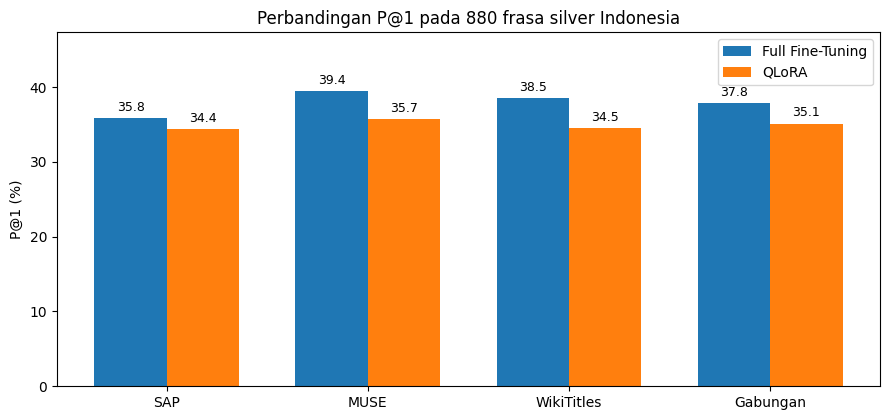

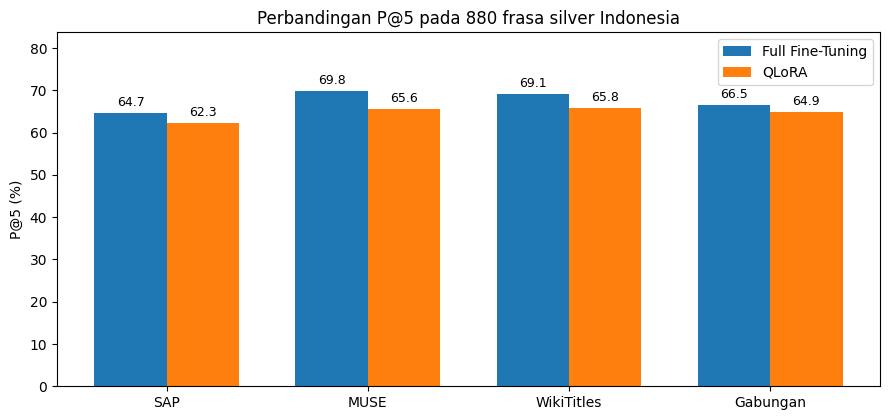

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

skor_tercatat = pd.DataFrame([
    ('SAP',35.80,34.43,64.66,62.27),
    ('MUSE',39.43,35.68,69.77,65.57),
    ('WikiTitles',38.52,34.55,69.09,65.80),
    ('Gabungan',37.84,35.11,66.48,64.89),
], columns=['Tahap','P@1 Full','P@1 QLoRA','P@5 Full','P@5 QLoRA'])

def gambar_perbandingan(df,metrik):
    fig,ax=plt.subplots(figsize=(9,4.3))
    x=np.arange(len(df)); w=0.36
    a=ax.bar(x-w/2,df[f'{metrik} Full'],w,label='Full Fine-Tuning')
    b=ax.bar(x+w/2,df[f'{metrik} QLoRA'],w,label='QLoRA')
    ax.bar_label(a,fmt='%.1f',padding=3,fontsize=9)
    ax.bar_label(b,fmt='%.1f',padding=3,fontsize=9)
    ax.set_xticks(x,df['Tahap']);ax.set_ylabel(f'{metrik} (%)')
    ax.set_ylim(0, max(df[f'{metrik} Full'].max(),df[f'{metrik} QLoRA'].max())*1.2)
    ax.legend();ax.set_title(f'Perbandingan {metrik} pada 880 frasa silver Indonesia')
    fig.tight_layout();plt.show()

for metrik in ('P@1','P@5'):
    gambar_perbandingan(skor_tercatat,metrik)

<a id="diskusi"></a>
## 6. Diskusi

**Akurasi dan efisiensi.** Full FT + MUSE mencapai P@1 39,43% dan P@5 69,77% pada 880 query silver. Selisih P@1 dan P@5 memperlihatkan bahwa sebagian CUI acuan dapat ditemukan pada kandidat peringkat 2–5 walaupun tidak berada di urutan pertama. QLoRA mempertahankan sebagian besar performa SAP dasar dengan parameter terlatih jauh lebih sedikit, tetapi tidak otomatis lebih cepat.

**Thailand vs Indonesia.** Dalam reproduksi TH, penambahan WikiTitles dan gabungan meningkatkan P@1 lebih besar daripada MUSE saja. Dalam adaptasi Indonesia, MUSE justru menjadi yang terbaik pada Full FT. Pada dataset unggahan, MUSE ID lebih banyak daripada MUSE TH; pasangan WikiTitles ID juga lebih banyak dan mengandung banyak nama dengan ejaan identik Inggris–Indonesia. Hal itu memberikan **hipotesis** bahwa bentuk kata serapan/nama ilmiah, komposisi bitext, dan jumlah data dapat memengaruhi transfer. Namun **skor absolut Indonesia vs Thailand tidak dapat dijadikan perbandingan kemampuan bahasa**: UMLS berbeda tahun, benchmark Indonesia berasal dari terjemahan dan tersaring menjadi 880 query, sedangkan TH adalah 1.000 query asli, dan komposisi data transfer berbeda.

**Mengapa prediksi masih keliru?** Beberapa penyebab yang mungkin adalah ambiguitas CUI, alias atau istilah yang tidak tersedia di ruang kandidat, keterbatasan keselarasan embedding, dan kesalahan penerjemahan silver. Ini **hipotesis umum**, bukan hasil audit prediksi per frasa yang sudah divalidasi.

**Batasan:** belum ada evaluasi gold teranotasi ahli, uji signifikansi berpasangan yang lengkap, dan klasifikasi NIL. Tidak mengklaim model siap digunakan untuk keputusan klinis. UMLS berlisensi tidak dipublikasikan.

<a id="kesimpulan"></a>
## 7. Kesimpulan

1. Reproduksi parsial Liu dkk. (2021) mencapai skor P@1 yang berbeda paling besar 0,8 poin dari angka acuan pada kondisi yang diuji.
2. Adaptasi SAP berbasis UMLS 2026AA dengan full fine-tuning mencapai P@1 35,80% pada benchmark silver Indonesia; **transfer MUSE menaikkan P@1 menjadi 39,43%**.
3. QLoRA menghemat memori pelatihan SAP dasar dengan kompromi penurunan akurasi. Penyajian skor dibatasi pada benchmark silver dan belum merupakan validasi klinis.

<a id="futureworks"></a>
## 8. Future Works

Validasi manual subset istilah medis oleh penilai dwibahasa, uji perbandingan dengan NLLB atau penerjemah alternatif, penyelidikan efek nama identik terhadap skor, evaluasi pasangan prediksi dengan uji statistik, eksperimen NIL, dan pengujian pada narasi medis Indonesia yang sebenarnya. Jika digunakan dalam aplikasi, model retrieval harus ditempatkan sebagai pemberi kandidat untuk pemeriksaan manusia.

<a id="output"></a>
## 9. Output, File Model, dan Download ke Komputer

**Output final project:**

- **Notebook:** isi tautan Colab atau GitHub setelah notebook ini diunggah ke repo kelompok.
- **Model terbaik:** **Full Fine-Tuning + MUSE**, P@1 39,43% dan P@5 69,77% pada benchmark silver. Checkpoint berada di Drive dengan folder `final/model` + `final/tokenizer`.
- **Slide:** isi tautan PPT/PDF setelah materi presentasi selesai.

**Format yang disarankan:** model Hugging Face `.safetensors` beserta `config.json` dan tokenizer adalah format utama yang aman dan praktis untuk dimuat kembali; untuk memenuhi contoh `.pt` pada guidebook, kode berikut dapat menambah state dict PyTorch `.pt`. File `.pt` sendirian **belum cukup** tanpa arsitektur/tokenizer. `.onnx` tidak wajib dan bukan alasan harus membuat deployment.

**Keamanan:** paket ekspor hanya berisi bobot model, tokenizer, dan metadata eksperimen, **tidak** berisi MRCONSO, pasangan SAP, atau kamus UMLS privat. Periksa ketentuan redistribusi checkpoint terlatih sebelum membuat tautan unduhan publik.

In [52]:
from pathlib import Path
import json, shutil
from datetime import datetime, timezone
from google.colab import drive

drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/sapbert_id_kc_paper_2026AA')
EXP2_CANDIDATES = [PROJECT_ROOT/'experiment_2_en_id', PROJECT_ROOT]
BEST_MODE = 'full'
BEST_VARIANT = 'muse'
BEST_TAG = 'cp1_loss_sharded_v1'
EXPORT_PT = False
DOWNLOAD_ZIP_TO_COMPUTER = True

candidate_finals = [p/'runs'/f'exp2_{BEST_VARIANT}_{BEST_MODE}_{BEST_TAG}'/'final'
                    for p in EXP2_CANDIDATES]
source = next((p for p in candidate_finals if (p/'training_completed.json').is_file()
               and (p/'model'/'config.json').is_file()
               and (p/'tokenizer').is_dir()), None)
if source is None:
    raise FileNotFoundError('Checkpoint terbaik belum ditemukan. Periksa folder Drive: '+
                            '; '.join(map(str,candidate_finals)))

export_dir = Path('/content/MCN_ID_FullFT_MUSE')
if export_dir.exists():
    shutil.rmtree(export_dir)
export_dir.mkdir(parents=True)
shutil.copytree(source/'model', export_dir/'model')
shutil.copytree(source/'tokenizer', export_dir/'tokenizer')
metadata = json.loads((source/'training_completed.json').read_text(encoding='utf-8'))
(export_dir/'metadata.json').write_text(json.dumps({
    'judul':'Normalisasi Konsep Medis Lintas Bahasa yang Efisien Parameter untuk Bahasa Indonesia',
    'metode':'XLM-R + SAP UMLS 2026AA, full fine-tuning dilanjutkan MUSE EN-ID',
    'benchmark':'880 query XL-BEL EN→ID, silver machine translation, bukan gold',
    'p_at_1_tercatat':39.43,'p_at_5_tercatat':69.77,'mrr_tercatat':0.5335,
    'sumber_checkpoint':str(source),'training_meta':metadata,
    'diekspor_utc':datetime.now(timezone.utc).isoformat(),
},ensure_ascii=False,indent=2),encoding='utf-8')
print('Bobot dan tokenizer tersalin:', export_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Bobot dan tokenizer tersalin: /content/MCN_ID_FullFT_MUSE


### 9.1 Tambahkan file `.pt` (opsional)

Aktifkan `EXPORT_PT=True` untuk menghasilkan `encoder_full_muse.pt` dari checkpoint Hugging Face. Proses ini memerlukan RAM lokal karena bobot model disalin ke representasi PyTorch. File `.safetensors` asli tetap dipertahankan.

In [48]:
if EXPORT_PT:
    import torch
    from transformers import AutoModel
    model_cpu = AutoModel.from_pretrained(str(export_dir/'model'), torch_dtype=torch.float32)
    torch.save(model_cpu.state_dict(), export_dir/'encoder_full_muse.pt')
    del model_cpu
    print('Model PyTorch .pt dibuat:', export_dir/'encoder_full_muse.pt')
else:
    print('Ekspor .pt dilewati; file .safetensors tetap tersedia.')

Model PyTorch .pt dibuat: /content/MCN_ID_FullFT_MUSE/encoder_full_muse.pt


### 9.2 Kemas ZIP dan unduh ke perangkat

ZIP menyertakan model, tokenizer, metadata, dan `.pt` jika diaktifkan. Arsip ZIP dapat berukuran sekitar beberapa GB jika `.pt` dan `.safetensors` keduanya disertakan. Untuk unduhan yang terputus, salinan ZIP juga disimpan ke Drive pribadi.

In [53]:
from pathlib import Path
import shutil

export_root = Path('/content')
archive_base = export_root/'MCN_ID_FullFT_MUSE_Model_dan_Tokenizer'
archive_path = Path(shutil.make_archive(str(archive_base), 'zip',
                                         root_dir=str(export_dir.parent),
                                         base_dir=export_dir.name))
drive_exports = PROJECT_ROOT/'exports'
drive_exports.mkdir(parents=True, exist_ok=True)
backup_zip = drive_exports/archive_path.name
shutil.copy2(archive_path, backup_zip)
print('ZIP siap:', archive_path, f'{archive_path.stat().st_size/2**20:.1f} MiB')
print('Backup Drive:', backup_zip)


ZIP siap: /content/MCN_ID_FullFT_MUSE_Model_dan_Tokenizer.zip 859.3 MiB
Backup Drive: /content/drive/MyDrive/sapbert_id_kc_paper_2026AA/exports/MCN_ID_FullFT_MUSE_Model_dan_Tokenizer.zip


### 9.3 Cara memuat checkpoint yang diunduh

Ekstrak ZIP, lalu gunakan direktori `model/` dan `tokenizer/`. Kode di bawah menunjukkan cara mengecek model; **tidak** menjalankan pencarian CUI tanpa kamus kandidat dan indeks embedding.

In [54]:
from transformers import AutoModel, AutoTokenizer

LOKASI_MODEL = '/content/MCN_ID_FullFT_MUSE'
model = AutoModel.from_pretrained(f'{LOKASI_MODEL}/model').eval()
tokenizer = AutoTokenizer.from_pretrained(f'{LOKASI_MODEL}/tokenizer')
input_batch = tokenizer(['diabetes', 'penyakit jantung'], return_tensors='pt',
                        padding=True, truncation=True, max_length=25)
with __import__('torch').inference_mode():
    embedding = model(**input_batch).last_hidden_state[:, 0, :]
print('Bentuk embedding CLS:', tuple(embedding.shape))

Bentuk embedding CLS: (2, 768)


### 9.5 Download model ke komputer — sel terakhir

Jalankan sel terakhir ini **setelah ZIP selesai dibuat**. Salinan ZIP tetap tersedia pada folder Google Drive pribadi `exports/`. Untuk arsip berukuran besar yang terputus melalui browser, unduh salinan dari Drive.

In [55]:
from google.colab import files
assert archive_path.is_file(), "Jalankan bagian ekspor dan kemas ZIP terlebih dahulu."
files.download(str(archive_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>